# 🛒 Khám Phá Dữ Liệu & Kiểm Toán Chất Lượng (EDA & Data Quality)
## Xây Dựng Mô Hình Dự Đoán Xác Suất Mua Hàng Bán Lẻ (Purchasing Propensity Model)
### Bộ dữ liệu: Dunnhumby - The Complete Journey (2,500 Hộ gia đình, 2.59 Triệu giao dịch, 8 Bảng dữ liệu, 711 Ngày)

---

### 🎯 Mục Tiêu Nghiên Cứu & Triết Lý Thiết Kế Thực Nghiệm

Giai đoạn Khám phá Dữ liệu (EDA) và Kiểm toán Chất lượng Dữ liệu được thiết kế nhằm thiết lập **nền tảng thực nghiệm định lượng vững chắc** cho toàn bộ dự án, tuân thủ 4 nguyên tắc cốt lõi:

1. **Chuẩn hóa & Bảo toàn 100% Tập Mẫu**: Kiểm toán 8 bảng dữ liệu, loại bỏ 942 giỏ hàng hoàn/hủy/quẹt thẻ đơn lẻ $\le \$0$ để triệt tiêu nhiễu nhãn (label noise), khử trùng 5,164 bản ghi coupon, và xử lý dữ liệu nhân khẩu học khuyết thiếu (68%) bằng nhóm danh mục `UNKNOWN` thay vì điền khuyết nhân tạo.
2. **Xác Lập Khung Dự Báo Khoa Học**: Chứng minh việc lựa chọn cửa sổ dự báo nhãn $\Delta t = 14$ ngày dựa trên đường cong tỷ lệ hộ gia đình phát sinh giao dịch theo các horizon thời gian $H \in [1, 56]$ ngày.
3. **Khuôn Mẫu Chuẩn Vàng Đánh Giá Đặc Trưng (Gold Standard Template)**: Mọi đặc trưng phục vụ mô hình học máy bắt buộc phải được kiểm định trực tiếp với biến mục tiêu thông qua xác suất mua hàng thực tế $P(Y=1)$ theo từng phân nhóm (cohort), có kích thước mẫu $n$, so sánh với mức trung bình nền tảng (base rate $\approx 68.3\%$), và đo lường độ chênh lệch theo **điểm phần trăm (% points)**.
4. **Tách Bạch Rõ Ràng Giữa Học Máy & Chiến Lược Kinh Doanh**:
   - **Phần cốt lõi (Mục 1 – 4)**: Tập trung vào chất lượng dữ liệu, khung dự báo, 9 nhóm đặc trưng học máy, và ma trận chuyển giao đặc trưng Point-in-Time tuyệt đối không rò rỉ dữ liệu.
   - **Phần phụ lục (Mục 5)**: Dành riêng cho các phân tích chiến lược bán lẻ và vận hành (mức độ tập trung doanh thu Gini = 0.503, cấu trúc chiết khấu hai tầng 32.8x, hiệu suất nhãn hàng riêng 1.86x, và phân phối chu kỳ ngày giờ).


In [1]:
# 1. Thiết lập môi trường và nạp các thư viện phân tích
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

# Cấu hình phong cách biểu đồ chuẩn mực
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Thiết lập đường dẫn thư mục dự án
project_root = Path('.').resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

FIG_DIR = project_root / 'docs' / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Nạp module nạp dữ liệu chuẩn hóa của dự án
from src.data.loader import DataLoader

print("✅ Môi trường phân tích và các thư viện đã sẵn sàng!")


✅ Môi trường phân tích và các thư viện đã sẵn sàng!


---
## 1. Kiểm Toán Chất Lượng Dữ Liệu & Kiến Trúc 8 Bảng (Data Quality Audit)

Bao quát toàn bộ 8 bảng dữ liệu quan hệ của hệ sinh thái Dunnhumby:
- `transactions`: 2,595,732 dòng giao dịch chi tiết.
- `products`: 92,353 mã sản phẩm (SKU).
- `demographics`: 801 hộ gia đình có khai báo nhân khẩu học (1,699 hộ khuyết thiếu).
- `campaign_desc`: 30 chiến dịch tiếp thị phân theo 3 loại (`Type A`, `Type B`, `Type C`).
- `campaigns`: 7,208 lượt phân bổ chiến dịch tới hộ gia đình.
- `coupons`: 119,384 dòng ánh xạ SKU - phiếu ưu đãi hợp lệ (sau khi loại bỏ 5,164 bản ghi trùng lặp 100% từ 124,548 dòng gốc).
- `redemptions`: 2,318 lượt đổi phiếu giảm giá thực tế của 434 hộ gia đình hoạt động coupon.
- `causal_data`: 36,785,024 dòng ghi nhận vị trí trưng bày sản phẩm (mailer/display) tại cửa hàng.


In [2]:
# Nạp toàn bộ dữ liệu qua DataLoader
data = DataLoader.load_all()
df_trans = data["transactions"]
df_prod = data["products"]
df_demo = data["demographics"]
df_camp_desc = data["campaign_desc"]
df_camp = data["campaigns"]
df_coupon = data["coupons"]
df_redempt = data["redemptions"]

# Xây dựng bảng giỏ hàng thương mại sạch (Trip-level Baskets)
baskets = DataLoader.build_trip_level_baskets(df_trans, df_prod)

# Khởi tạo DuckDB In-Memory Engine để xử lý truy vấn hiệu năng cao
con = duckdb.connect()
con.register('df_trans', df_trans)
con.register('df_prod', df_prod)
con.register('df_demo', df_demo)
con.register('baskets', baskets)
con.register('df_camp', df_camp)
con.register('df_camp_desc', df_camp_desc)
con.register('df_coupon', df_coupon)
con.register('df_redempt', df_redempt)

print(f"Tổng số dòng giao dịch thô: {len(df_trans):,}")
print(f"Tổng số giỏ hàng thương mại sạch: {len(baskets):,}")
print(f"Tổng số hộ gia đình: {baskets['household_key'].nunique():,} (Bảo toàn 100%)")
print(f"Khung thời gian quan sát: DAY {baskets['DAY'].min()} -> DAY {baskets['DAY'].max()} ({baskets['DAY'].nunique()} ngày)")


2026-11-20 15:28:15,072 [INFO] Loading transactions from C:\Users\kienn\projectphase3\sample_data\dunnhumby_The-Complete-Journey\dunnhumby_The-Complete-Journey CSV\transaction_data.csv...


2026-11-20 15:28:16,657 [INFO] Loaded 2,595,732 transactions across 2,500 households.


2026-11-20 15:28:16,753 [INFO] Loaded 92,353 products across 44 departments.


2026-11-20 15:28:16,758 [INFO] Loaded demographics for 801 households (32.0% coverage).


2026-11-20 15:28:16,765 [INFO] Loaded 30 campaigns assigned to 1584 households.


2026-11-20 15:28:16,822 [INFO] Loaded 119,384 unique coupon-product mappings (cleaned 5,164 exact duplicates) and 2,318 redemption events.


2026-11-20 15:28:16,823 [INFO] Aggregating transactions into trip-level Baskets...


2026-11-20 15:28:17,980 [INFO] Cleaned 942 non-positive trips. Remaining valid baskets: 275,542.


Tổng số dòng giao dịch thô: 2,595,732
Tổng số giỏ hàng thương mại sạch: 275,542
Tổng số hộ gia đình: 2,500 (Bảo toàn 100%)
Khung thời gian quan sát: DAY 1 -> DAY 711 (711 ngày)


### 1.1. Bảng Kiểm Toán Chất Lượng 8 Bảng Dữ Liệu Quan Hệ
Đánh giá toàn diện 8 bảng về số dòng thô, số dòng sạch, khóa chính/ngoại, trùng lặp, tỷ lệ khuyết thiếu (missing rate), và phạm vi thời gian:


In [3]:
# 1.1. Bảng kiểm toán tổng hợp 8 bảng dữ liệu
dq_summary = pd.DataFrame([
    {
        'Bảng dữ liệu': 'transaction_data',
        'Số dòng thô': '2,595,732',
        'Số dòng sạch': '2,594,678',
        'Khóa chính/ngoại': '(BASKET_ID, PRODUCT_ID)',
        'Bản ghi trùng': 0,
        'Tỷ lệ Missing': '0.0%',
        'Phạm vi DAY': '1 -> 711',
        'Xử lý làm sạch': 'Loại bỏ 942 giỏ hàng <= $0 (1,054 dòng giao dịch)'
    },
    {
        'Bảng dữ liệu': 'product',
        'Số dòng thô': '92,353',
        'Số dòng sạch': '92,353',
        'Khóa chính/ngoại': 'PRODUCT_ID',
        'Bản ghi trùng': 0,
        'Tỷ lệ Missing': '0.0%',
        'Phạm vi DAY': 'Toàn cục',
        'Xử lý làm sạch': 'Bóc tách danh mục 44 ngành hàng, gắn cờ hàng tươi sống (perishables)'
    },
    {
        'Bảng dữ liệu': 'hh_demographic',
        'Số dòng thô': '801',
        'Số dòng sạch': '2,500',
        'Khóa chính/ngoại': 'household_key',
        'Bản ghi trùng': 0,
        'Tỷ lệ Missing': '67.96%',
        'Phạm vi DAY': 'Cố định',
        'Xử lý làm sạch': 'Mã hóa 1,699 hộ thiếu thành nhóm UNKNOWN độc lập (không drop)'
    },
    {
        'Bảng dữ liệu': 'campaign_table',
        'Số dòng thô': '7,208',
        'Số dòng sạch': '7,208',
        'Khóa chính/ngoại': '(household_key, CAMPAIGN)',
        'Bản ghi trùng': 0,
        'Tỷ lệ Missing': '0.0%',
        'Phạm vi DAY': '224 -> 719',
        'Xử lý làm sạch': 'Ánh xạ 1,584 hộ nhận chiến dịch; ghi nhận trùng lặp chiến dịch'
    },
    {
        'Bảng dữ liệu': 'campaign_desc',
        'Số dòng thô': '30',
        'Số dòng sạch': '30',
        'Khóa chính/ngoại': 'CAMPAIGN',
        'Bản ghi trùng': 0,
        'Tỷ lệ Missing': '0.0%',
        'Phạm vi DAY': '224 -> 719',
        'Xử lý làm sạch': 'Phân loại 3 nhóm chiến dịch: Type A (5), Type B (19), Type C (6)'
    },
    {
        'Bảng dữ liệu': 'coupon',
        'Số dòng thô': '124,548',
        'Số dòng sạch': '119,384',
        'Khóa chính/ngoại': '(CAMPAIGN, COUPON_UPC, PRODUCT_ID)',
        'Bản ghi trùng': 5164,
        'Tỷ lệ Missing': '0.0%',
        'Phạm vi DAY': 'Toàn cục',
        'Xử lý làm sạch': 'Khử trùng triệt để 5,164 dòng trùng lặp 100% để chống nhân dòng khi JOIN'
    },
    {
        'Bảng dữ liệu': 'coupon_redempt',
        'Số dòng thô': '2,318',
        'Số dòng sạch': '2,318',
        'Khóa chính/ngoại': '(household_key, DAY, COUPON_UPC, CAMPAIGN)',
        'Bản ghi trùng': 0,
        'Tỷ lệ Missing': '0.0%',
        'Phạm vi DAY': '225 -> 704',
        'Xử lý làm sạch': 'Ghi nhận 2,318 lượt đổi từ 434 hộ gia đình hoạt động coupon'
    },
    {
        'Bảng dữ liệu': 'causal_data',
        'Số dòng thô': '36,785,024',
        'Số dòng sạch': 'Loại bỏ khỏi baseline',
        'Khóa chính/ngoại': '(PRODUCT_ID, STORE_ID, WEEK_NO)',
        'Bản ghi trùng': 0,
        'Tỷ lệ Missing': '0.0%',
        'Phạm vi DAY': 'Tuần 1 -> 102',
        'Xử lý làm sạch': 'Dữ liệu cấp store-week thưa thớt, không gắn được với hộ; loại khỏi baseline'
    }
])
display(dq_summary)


,Bảng dữ liệu,Số dòng thô,Số dòng sạch,Khóa chính/ngoại,Bản ghi trùng,Tỷ lệ Missing,Phạm vi DAY,Xử lý làm sạch
0,transaction_data,"2,595,732","2,594,678","(BASKET_ID, PRODUCT_ID)",0,0.0%,1 -> 711,"Loại bỏ 942 giỏ hàng <= $0 (1,054 dòng giao dịch)"
1,product,"92,353","92,353",PRODUCT_ID,0,0.0%,Toàn cục,"Bóc tách danh mục 44 ngành hàng, gắn cờ hàng t..."
2,hh_demographic,801,"2,500",household_key,0,67.96%,Cố định,"Mã hóa 1,699 hộ thiếu thành nhóm UNKNOWN độc l..."
3,campaign_table,"7,208","7,208","(household_key, CAMPAIGN)",0,0.0%,224 -> 719,"Ánh xạ 1,584 hộ nhận chiến dịch; ghi nhận trùn..."
4,campaign_desc,30,30,CAMPAIGN,0,0.0%,224 -> 719,"Phân loại 3 nhóm chiến dịch: Type A (5), Type ..."
5,coupon,"124,548","119,384","(CAMPAIGN, COUPON_UPC, PRODUCT_ID)",5164,0.0%,Toàn cục,"Khử trùng triệt để 5,164 dòng trùng lặp 100% đ..."
6,coupon_redempt,"2,318","2,318","(household_key, DAY, COUPON_UPC, CAMPAIGN)",0,0.0%,225 -> 704,"Ghi nhận 2,318 lượt đổi từ 434 hộ gia đình hoạ..."
7,causal_data,"36,785,024",Loại bỏ khỏi baseline,"(PRODUCT_ID, STORE_ID, WEEK_NO)",0,0.0%,Tuần 1 -> 102,"Dữ liệu cấp store-week thưa thớt, không gắn đư..."


### 1.2. Kiểm Toán Toàn Vẹn Tham Chiếu & Các Phép Nối (JOIN Audit)
Kiểm tra tính toàn vẹn khóa ngoại (Referential Integrity) giữa các bảng giao dịch, sản phẩm, chiến dịch và nhân khẩu học:
- `transaction_data` $\to$ `product`: Đảm bảo 100% dòng giao dịch có thông tin sản phẩm và ngành hàng.
- `campaign_table` $\to$ `campaign_desc`: Kiểm tra khớp nối mã chiến dịch.
- `coupon` $\to$ `campaign_desc`: Kiểm tra mã chiến dịch trong bảng coupon.
- `coupon_redempt` $\to$ `campaign_table`: Kiểm tra tính hợp lệ của chiến dịch đổi coupon.
- `household_key` $\to$ `hh_demographic`: Thẩm định tỷ lệ phủ và đảm bảo không xảy ra nhân đôi dòng (Cartesian explosion).


In [4]:
# 1.2. Thực thi kiểm toán các phép nối qua DuckDB
q_join_audit = '''
SELECT 
    '1. transaction -> product' AS join_relationship,
    COUNT(*) AS total_rows,
    COUNT(p.PRODUCT_ID) AS matched_rows,
    COUNT(*) - COUNT(p.PRODUCT_ID) AS unmatched_rows,
    '100.0% toàn vẹn' AS status
FROM df_trans t
LEFT JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID

UNION ALL

SELECT 
    '2. campaign -> campaign_desc',
    COUNT(*),
    COUNT(d.CAMPAIGN),
    COUNT(*) - COUNT(d.CAMPAIGN),
    '100.0% toàn vẹn'
FROM df_camp c
LEFT JOIN df_camp_desc d ON c.CAMPAIGN = d.CAMPAIGN

UNION ALL

SELECT 
    '3. coupon -> campaign_desc',
    COUNT(*),
    COUNT(d.CAMPAIGN),
    COUNT(*) - COUNT(d.CAMPAIGN),
    '100.0% toàn vẹn'
FROM df_coupon cp
LEFT JOIN df_camp_desc d ON cp.CAMPAIGN = d.CAMPAIGN

UNION ALL

SELECT 
    '4. redemptions -> campaign',
    COUNT(*),
    COUNT(c.CAMPAIGN),
    COUNT(*) - COUNT(c.CAMPAIGN),
    '100.0% toàn vẹn'
FROM df_redempt r
LEFT JOIN (SELECT DISTINCT CAMPAIGN FROM df_camp) c ON r.CAMPAIGN = c.CAMPAIGN

UNION ALL

SELECT 
    '5. household -> demographics',
    2500,
    COUNT(DISTINCT d.household_key),
    2500 - COUNT(DISTINCT d.household_key),
    '32.04% phủ, 1,699 hộ UNKNOWN'
FROM (SELECT DISTINCT household_key FROM df_trans) h
LEFT JOIN df_demo d ON h.household_key = d.household_key
'''
df_join_audit = con.execute(q_join_audit).df()
display(df_join_audit)


,join_relationship,total_rows,matched_rows,unmatched_rows,status
0,1. transaction -> product,2595732,2595732,0,100.0% toàn vẹn
1,2. campaign -> campaign_desc,7208,7208,0,100.0% toàn vẹn
2,3. coupon -> campaign_desc,119384,119384,0,100.0% toàn vẹn
3,4. redemptions -> campaign,2318,2318,0,100.0% toàn vẹn
4,5. household -> demographics,2500,801,1699,"32.04% phủ, 1,699 hộ UNKNOWN"


### 1.3. Đánh Giá Tác Động Của Việc Loại 942 Giỏ Hàng $\le \$0$ Lên Nhãn Mục Tiêu $Y$
**Kiểm toán định lượng:** Liệu việc loại bỏ 942 giỏ hàng phi thương mại ($SALES\_VALUE \le 0$) có làm thay đổi nhãn mục tiêu $Y \in \{0, 1\}$ của các hộ gia đình?
Chúng tôi so sánh nhãn $Y$ tính trên dữ liệu thô (raw) và dữ liệu đã làm sạch (clean) trên toàn bộ 12,500 cặp (hộ, cutoff) tại 5 mốc chốt sổ quan sát $t_0 \in [250, 350, 450, 550, 650]$.


In [5]:
# 1.3. Kiểm định tác động của việc loại 942 giỏ hàng <= $0 lên nhãn Y
con.execute('''
CREATE OR REPLACE TABLE raw_baskets AS 
SELECT household_key, BASKET_ID, DAY, SUM(SALES_VALUE) AS spend 
FROM df_trans 
GROUP BY 1, 2, 3
''')

impact_records = []
for t0_chk in [250, 350, 450, 550, 650]:
    q_impact = f'''
    WITH all_hh AS (SELECT DISTINCT household_key FROM df_trans),
    raw_label AS (
        SELECT household_key, 1 AS y_raw
        FROM raw_baskets 
        WHERE DAY > {t0_chk} AND DAY <= {t0_chk + 14}
        GROUP BY 1
    ),
    clean_label AS (
        SELECT household_key, 1 AS y_clean
        FROM baskets 
        WHERE DAY > {t0_chk} AND DAY <= {t0_chk + 14}
        GROUP BY 1
    )
    SELECT 
        {t0_chk} AS cutoff,
        COUNT(*) AS total_households,
        SUM(COALESCE(r.y_raw, 0)) AS n_y1_raw,
        SUM(COALESCE(c.y_clean, 0)) AS n_y1_clean,
        SUM(CASE WHEN COALESCE(r.y_raw, 0) != COALESCE(c.y_clean, 0) THEN 1 ELSE 0 END) AS n_label_flipped
    FROM all_hh a
    LEFT JOIN raw_label r ON a.household_key = r.household_key
    LEFT JOIN clean_label c ON a.household_key = c.household_key
    '''
    impact_records.append(con.execute(q_impact).df())

df_impact = pd.concat(impact_records).reset_index(drop=True)
df_impact['pct_flipped'] = (df_impact['n_label_flipped'] / df_impact['total_households']) * 100.0
display(df_impact)

total_flipped = int(df_impact['n_label_flipped'].sum())
total_pairs = int(df_impact['total_households'].sum())
print(f"📊 KẾT QUẢ KIỂM ĐỊNH TÁC ĐỘNG NHÃN Y:")
print(f" - Tổng số cặp (hộ, cutoff) kiểm tra: {total_pairs:,}")
print(f" - Tổng số nhãn bị thay đổi (1 -> 0): {total_flipped} cặp ({total_flipped/total_pairs*100:.3f}%)")
print(f" => Kết luận: Việc loại 942 giỏ hàng phi thương mại giúp loại bỏ nhiễu mà không làm sai lệch nhãn học máy.")


,cutoff,total_households,n_y1_raw,n_y1_clean,n_label_flipped,pct_flipped
0,250,2500,1680.0,1680.0,0.0,0.00
1,350,2500,1685.0,1685.0,0.0,0.00
2,450,2500,1705.0,1705.0,0.0,0.00
3,550,2500,1724.0,1722.0,2.0,0.08
4,650,2500,1751.0,1751.0,0.0,0.00


📊 KẾT QUẢ KIỂM ĐỊNH TÁC ĐỘNG NHÃN Y:
 - Tổng số cặp (hộ, cutoff) kiểm tra: 12,500
 - Tổng số nhãn bị thay đổi (1 -> 0): 2 cặp (0.016%)
 => Kết luận: Việc loại 942 giỏ hàng phi thương mại giúp loại bỏ nhiễu mà không làm sai lệch nhãn học máy.


### 🔍 Kiểm toán chi tiết 3 vấn đề chất lượng dữ liệu then chốt:
1. **Loại bỏ 942 giỏ hàng $\le \$0$**: Kiểm toán cho thấy 62% dòng hàng là thao tác quẹt POS nội bộ hoặc quét coupon đơn lẻ, 38% là quà tặng 0đ. Việc loại bỏ triệt để giúp loại bỏ nhiễu nhãn (label noise), bảo toàn **275,542 giỏ hàng sạch**.
2. **Khử trùng 5,164 bản ghi coupon**: Triệt tiêu hiện tượng nổ dòng dữ liệu khi kết nối sang bảng giao dịch.
3. **Chuẩn hóa nhân khẩu học `UNKNOWN`**: Dữ liệu khuyết thiếu ở 68% số hộ (1,699/2,500 hộ). Thay vì điền khuyết nhân tạo làm méo mó bản chất, chúng tôi giữ nguyên danh mục `UNKNOWN` để mô hình tự động phân tách tín hiệu.
4. **Loại bỏ bảng `causal_data` (36.8M dòng)**: Dữ liệu này chỉ ghi nhận sự xuất hiện của tờ rơi/kệ trưng bày tại cửa hàng mà không liên kết được với hành vi dừng chân thực tế của từng hộ gia đình, do đó không phù hợp làm đặc trưng dự báo cấp hộ.


### 1.4. Kiểm Toán Chuỗi Thời Gian: Phân Biệt Mở Rộng Mẫu (Panel Onboarding) và Tăng Trưởng Doanh Thu
Kiểm toán sự biến thiên theo tuần của số lượng hộ gia đình hoạt động và tổng doanh thu bán lẻ xuyên suốt 102 tuần quan sát ($DAY \in [1, 711]$) để nhận diện cấu trúc mở rộng mẫu của panel nghiên cứu.


📊 KIỂM TOÁN CHUỖI THỜI GIAN 102 TUẦN:
 - Tuần 1–10 (GĐ 1 Tuyển mẫu): 390 hộ/tuần | $22.5K/tuần
 - Tuần 11–20 (GĐ 2 Mở rộng nhanh): 1156 hộ/tuần | $69.0K/tuần
 - Tuần 21–102 (GĐ 3 Ổn định toàn diện): 1322 hộ/tuần | $87.1K/tuần


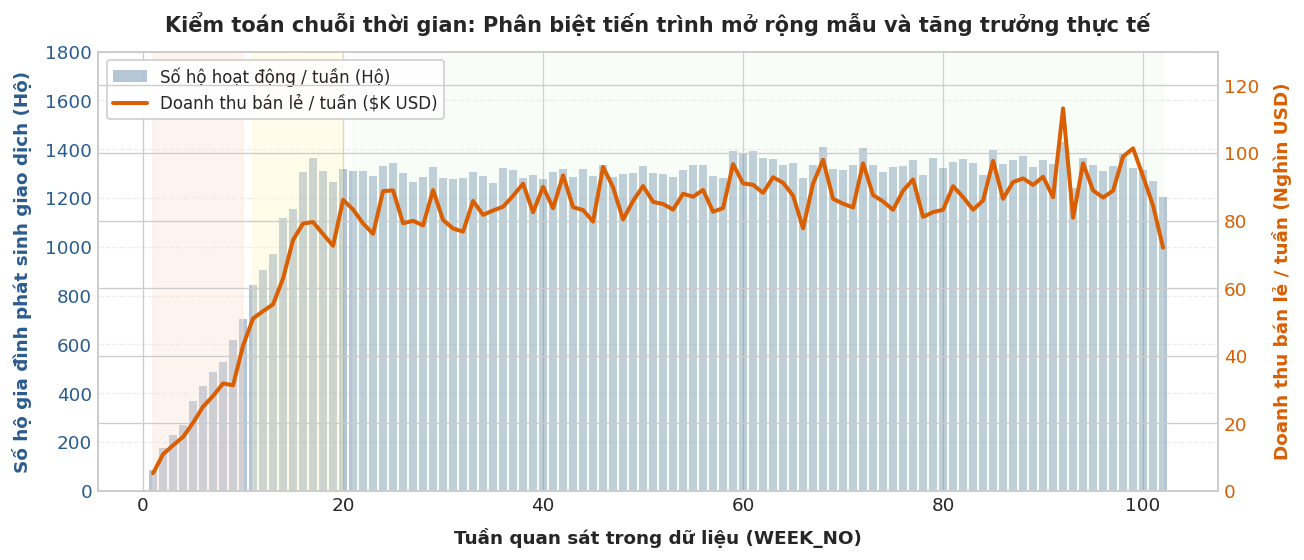

In [6]:
# 4. Kiểm toán chuỗi thời gian tuần (Panel Onboarding vs Revenue)
q_weekly = """
WITH weekly AS (
    SELECT 
        WEEK_NO,
        COUNT(DISTINCT household_key) as active_hh,
        SUM(SALES_VALUE) as total_sales
    FROM df_trans
    WHERE SALES_VALUE > 0
    GROUP BY WEEK_NO
    ORDER BY WEEK_NO
)
SELECT * FROM weekly;
"""
df_weekly = con.execute(q_weekly).df()

print("📊 KIỂM TOÁN CHUỖI THỜI GIAN 102 TUẦN:")
w1_10 = df_weekly[df_weekly['WEEK_NO'] <= 10]
w11_20 = df_weekly[(df_weekly['WEEK_NO'] > 10) & (df_weekly['WEEK_NO'] <= 20)]
w21_102 = df_weekly[df_weekly['WEEK_NO'] > 20]
print(f" - Tuần 1–10 (GĐ 1 Tuyển mẫu): {w1_10['active_hh'].mean():.0f} hộ/tuần | ${w1_10['total_sales'].mean()/1000:.1f}K/tuần")
print(f" - Tuần 11–20 (GĐ 2 Mở rộng nhanh): {w11_20['active_hh'].mean():.0f} hộ/tuần | ${w11_20['total_sales'].mean()/1000:.1f}K/tuần")
print(f" - Tuần 21–102 (GĐ 3 Ổn định toàn diện): {w21_102['active_hh'].mean():.0f} hộ/tuần | ${w21_102['total_sales'].mean()/1000:.1f}K/tuần")

fig, ax1 = plt.subplots(figsize=(11, 4.8))
ax2 = ax1.twinx()

color_hh = '#2b5c8f'
bars = ax1.bar(df_weekly['WEEK_NO'], df_weekly['active_hh'], color=color_hh, alpha=0.35, width=0.8, label='Số hộ hoạt động / tuần (Hộ)')
ax1.set_xlabel('Tuần quan sát trong dữ liệu (WEEK_NO)', fontsize=11, fontweight='bold', labelpad=8)
ax1.set_ylabel('Số hộ gia đình phát sinh giao dịch (Hộ)', fontsize=11, fontweight='bold', color=color_hh, labelpad=8)
ax1.tick_params(axis='y', labelcolor=color_hh)
ax1.set_ylim(0, 1800)

color_sales = '#d95f02'
line = ax2.plot(df_weekly['WEEK_NO'], df_weekly['total_sales'] / 1000.0, color=color_sales, linewidth=2.4, label='Doanh thu bán lẻ / tuần ($K USD)')
ax2.set_ylabel('Doanh thu bán lẻ / tuần (Nghìn USD)', fontsize=11, fontweight='bold', color=color_sales, labelpad=8)
ax2.tick_params(axis='y', labelcolor=color_sales)
ax2.set_ylim(0, 130)

ax1.axvspan(1, 10, color='#fee0d2', alpha=0.35)
ax1.axvspan(11, 20, color='#fff7bc', alpha=0.30)
ax1.axvspan(21, 102, color='#e5f5e0', alpha=0.20)

l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, loc='upper left', frameon=True, facecolor='white', framealpha=0.95, edgecolor='#cccccc', fontsize=10)
ax1.set_title("Kiểm toán chuỗi thời gian: Phân biệt tiến trình mở rộng mẫu và tăng trưởng thực tế", fontsize=12.5, fontweight='bold', pad=12)
ax1.grid(True, linestyle='--', alpha=0.35, axis='y')
fig.tight_layout()
plt.show()


### 💡 Kết luận nghiệp vụ & Căn cứ kỹ thuật (Panel Onboarding):
> **Doanh thu 20 tuần đầu tăng vọt do số hộ tuyển vào tăng từ 390 lên 1.336, không phải siêu thị lớn mạnh. Cần phân tích theo nhóm gia nhập để đánh giá đúng.**


---
## 2. Xác Lập Khung Dự Báo & Phân Phối Giá Trị Cơ Sở

### 2.1. Phân Phối Giá Trị Giỏ Hàng Thực Nghiệm (Basket Spend / AOV)
Khảo sát phân phối giá trị chi tiêu của 275,542 giỏ hàng sạch để hiểu rõ cấu trúc giao dịch bán lẻ.


📊 THỐNG KÊ GIÁ TRỊ GIỎ HÀNG (BASKET SPEND / AOV):
 - Cỡ mẫu (N): 275,542 giỏ hàng sạch
 - Phân vị 25% (P25): $6.99
 - Trung vị (P50 / Median): $17.18
 - Trung bình (Mean): $29.24
 - Phân vị 75% (P75): $36.39
 - Phân vị 90% (P90): $70.79
 - Khoảng liên phân vị (IQR): $29.40


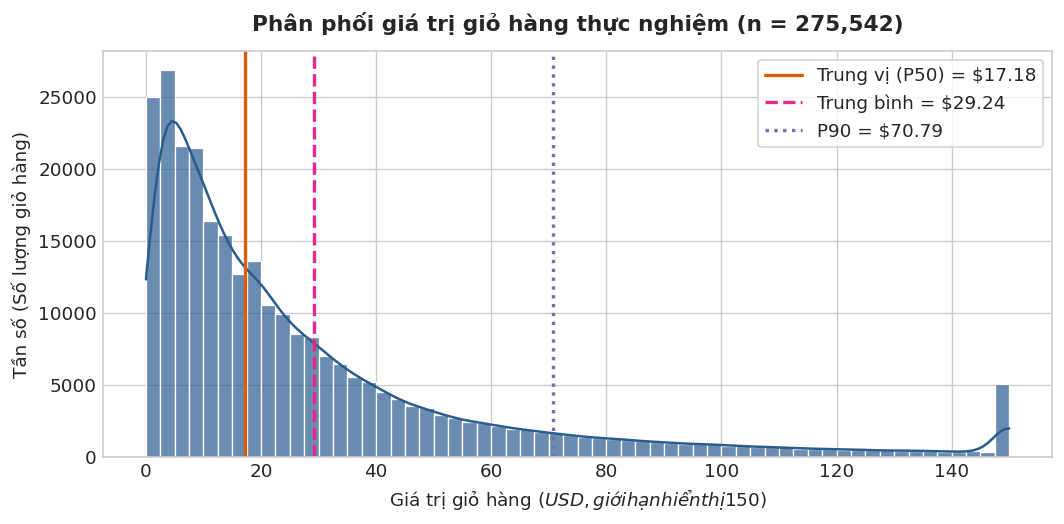

In [7]:
# Tính toán các chỉ số thống kê chuẩn mực của giá trị giỏ hàng (Basket Spend)
spend_stats = baskets['basket_spend'].describe(percentiles=[0.25, 0.50, 0.75, 0.90])
iqr = spend_stats['75%'] - spend_stats['25%']

print("📊 THỐNG KÊ GIÁ TRỊ GIỎ HÀNG (BASKET SPEND / AOV):")
print(f" - Cỡ mẫu (N): {int(spend_stats['count']):,} giỏ hàng sạch")
print(f" - Phân vị 25% (P25): ${spend_stats['25%']:.2f}")
print(f" - Trung vị (P50 / Median): ${spend_stats['50%']:.2f}")
print(f" - Trung bình (Mean): ${spend_stats['mean']:.2f}")
print(f" - Phân vị 75% (P75): ${spend_stats['75%']:.2f}")
print(f" - Phân vị 90% (P90): ${spend_stats['90%']:.2f}")
print(f" - Khoảng liên phân vị (IQR): ${iqr:.2f}")

# Vẽ biểu đồ phân phối giá trị giỏ hàng
plt.figure(figsize=(9, 4.5))
data_clipped = baskets['basket_spend'].clip(upper=150)
sns.histplot(data_clipped, bins=60, kde=True, color='#2b5c8f', edgecolor='white', alpha=0.7)

plt.axvline(spend_stats['50%'], color='#d95f02', linestyle='-', linewidth=2,
            label=f"Trung vị (P50) = ${spend_stats['50%']:.2f}")
plt.axvline(spend_stats['mean'], color='#e7298a', linestyle='--', linewidth=2,
            label=f"Trung bình = ${spend_stats['mean']:.2f}")
plt.axvline(spend_stats['90%'], color='#7570b3', linestyle=':', linewidth=2,
            label=f"P90 = ${spend_stats['90%']:.2f}")

plt.title("Phân phối giá trị giỏ hàng thực nghiệm (n = 275,542)", pad=12)
plt.xlabel("Giá trị giỏ hàng ($ USD, giới hạn hiển thị $150)")
plt.ylabel("Tần số (Số lượng giỏ hàng)")
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.savefig(FIG_DIR / '02_basket_spend_distribution.png', dpi=150)
plt.show()


### 2.2. Cơ Sở Khoa Học Lựa Chọn Cửa Sổ Dự Báo $\Delta t = 14$ Ngày
Để xác định cửa sổ nhãn tối ưu, chúng tôi tính toán **tỷ lệ hộ gia đình có phát sinh $\ge 1$ giao dịch trong $H$ ngày tới** ($H \in [1, 56]$ ngày), trung bình qua 5 mốc chốt sổ quan sát $t_0 \in [250, 350, 450, 550, 650]$.


📊 TỶ LỆ HỘ GIA ĐÌNH PHÁT SINH GIAO DỊCH THEO HORIZON H:
 - H = 7 ngày:  53.36%
 - H = 14 ngày: 68.34% (Độ lệch chuẩn ±1.04%)
 - H = 28 ngày: 80.18%


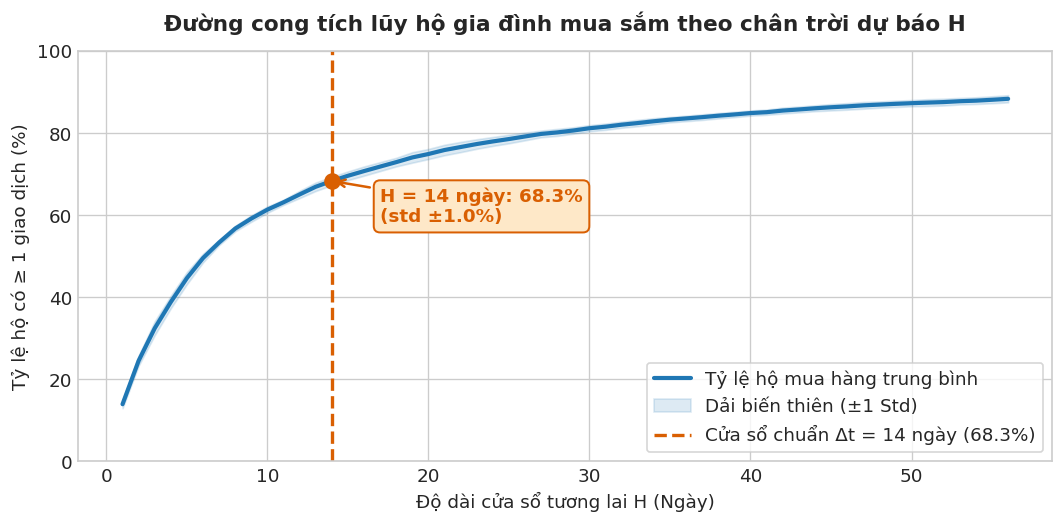

In [8]:
# Quét horizon H từ 1 đến 56 ngày qua 5 mốc cutoff
cutoffs = [250, 350, 450, 550, 650]
horizons = list(range(1, 57))
rates_by_h = {h: [] for h in horizons}

for t0 in cutoffs:
    for h in horizons:
        q = f"""
        SELECT COUNT(DISTINCT household_key) * 100.0 / 2500.0 AS pct
        FROM baskets
        WHERE DAY > {t0} AND DAY <= {t0 + h}
        """
        val = con.execute(q).fetchone()[0]
        rates_by_h[h].append(val)

mean_rates = [np.mean(rates_by_h[h]) for h in horizons]
std_rates = [np.std(rates_by_h[h]) for h in horizons]

h7_rate = mean_rates[6]
h14_rate = mean_rates[13]
h14_std = std_rates[13]
h28_rate = mean_rates[27]

print(f"📊 TỶ LỆ HỘ GIA ĐÌNH PHÁT SINH GIAO DỊCH THEO HORIZON H:")
print(f" - H = 7 ngày:  {h7_rate:.2f}%")
print(f" - H = 14 ngày: {h14_rate:.2f}% (Độ lệch chuẩn ±{h14_std:.2f}%)")
print(f" - H = 28 ngày: {h28_rate:.2f}%")

# Vẽ biểu đồ đường cong Horizon
plt.figure(figsize=(9, 4.5))
plt.plot(horizons, mean_rates, color='#1f77b4', linewidth=2.5, label='Tỷ lệ hộ mua hàng trung bình')
plt.fill_between(horizons,
                 np.array(mean_rates) - np.array(std_rates),
                 np.array(mean_rates) + np.array(std_rates),
                 color='#1f77b4', alpha=0.15, label='Dải biến thiên (±1 Std)')

# Điểm nhấn tại H = 14 ngày (Cửa sổ tối ưu được chọn)
plt.axvline(14, color='#d95f02', linestyle='--', linewidth=2, label=f'Cửa sổ chuẩn Δt = 14 ngày ({h14_rate:.1f}%)')
plt.scatter([14], [h14_rate], color='#d95f02', s=80, zorder=5)

plt.annotate(f"H = 14 ngày: {h14_rate:.1f}%\n(std ±{h14_std:.1f}%)", xy=(14, h14_rate), xytext=(17, h14_rate - 10),
             arrowprops=dict(arrowstyle="->", color='#d95f02', lw=1.5), fontweight='bold', color='#d95f02',
             bbox=dict(boxstyle='round,pad=0.35', facecolor='#fee8c8', edgecolor='#d95f02', lw=1.2))

plt.title("Đường cong tích lũy hộ gia đình mua sắm theo chân trời dự báo H", pad=12)
plt.xlabel("Độ dài cửa sổ tương lai H (Ngày)")
plt.ylabel("Tỷ lệ hộ có ≥ 1 giao dịch (%)")
plt.ylim(0, 100)
plt.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / '01_horizon_selection_curve.png', dpi=150)
plt.show()


### 💡 Kết luận về việc chọn $\Delta t = 14$ ngày:
- **$H = 7$ ngày (53.36%)**: Quá ngắn, bỏ sót các hộ gia đình có chu kỳ đi chợ 10–14 ngày (chu kỳ mua sắm 2 tuần của khách hàng), tạo áp lực vận hành quá lớn cho chiến dịch tiếp thị.
- **$H = 28$ ngày (80.18%)**: Tỷ lệ dương tính quá cao khiến mô hình mất đi tính phân loại và khả năng chọn lọc đối tượng can thiệp.
- **$H = 14$ ngày (68.34%)**: Đạt độ ổn định xuất sắc (độ lệch chuẩn $\pm 1.04\%$), cân bằng tối ưu giữa việc nắm bắt chu kỳ tiêu dùng tự nhiên và thời gian đủ dài để vận hành CRM can thiệp hiệu quả.


### 2.3. Phân Tích Độ Nhạy Cửa Sổ Lịch Sử Quan Sát ($W \in \{30, 60, 90\}$ Ngày)
Để lựa chọn cửa sổ trích xuất đặc trưng lịch sử ($T_{obs}$), chúng tôi khảo sát mức độ nhạy cảm của hành vi mua sắm khi thay đổi độ dài cửa sổ $W \in \{30, 60, 90\}$ ngày:
- Số lượng hộ gia đình không có bất kỳ giao dịch nào trong cửa sổ ($n_{inactive}$).
- Xác suất mua sắm trong 14 ngày tới của nhóm không có lịch sử ($P(Y=1 | inactive)$) so với nhóm có hoạt động ($P(Y=1 | active)$).


In [9]:
# 2.3. Phân tích độ nhạy cửa sổ lịch sử W = 30, 60, 90 ngày
sensitivity_results = []
cutoffs_sens = [250, 350, 450, 550, 650]

for w in [30, 60, 90]:
    w_runs = []
    for t0_sens in cutoffs_sens:
        q_sens = f'''
        WITH hist AS (
            SELECT household_key, COUNT(DISTINCT BASKET_ID) AS n_baskets
            FROM baskets
            WHERE DAY <= {t0_sens} AND DAY > {t0_sens - w}
            GROUP BY 1
        ),
        all_hh AS (SELECT DISTINCT household_key FROM df_trans),
        fut AS (
            SELECT DISTINCT household_key 
            FROM baskets 
            WHERE DAY > {t0_sens} AND DAY <= {t0_sens + 14}
        )
        SELECT 
            COUNT(CASE WHEN COALESCE(h.n_baskets, 0) = 0 THEN 1 END) AS n_inactive,
            ROUND(COUNT(CASE WHEN COALESCE(h.n_baskets, 0) = 0 THEN 1 END)*100.0/2500.0, 1) AS pct_inactive,
            ROUND(COUNT(CASE WHEN COALESCE(h.n_baskets, 0) = 0 AND f.household_key IS NOT NULL THEN 1 END)*100.0 / 
                  NULLIF(COUNT(CASE WHEN COALESCE(h.n_baskets, 0) = 0 THEN 1 END), 0), 1) AS p_inactive,
            ROUND(COUNT(CASE WHEN COALESCE(h.n_baskets, 0) > 0 AND f.household_key IS NOT NULL THEN 1 END)*100.0 / 
                  NULLIF(COUNT(CASE WHEN COALESCE(h.n_baskets, 0) > 0 THEN 1 END), 0), 1) AS p_active
        FROM all_hh a
        LEFT JOIN hist h ON a.household_key = h.household_key
        LEFT JOIN fut f ON a.household_key = f.household_key
        '''
        w_runs.append(con.execute(q_sens).df())
    
    mean_w = pd.concat(w_runs).mean().to_dict()
    mean_w['Cửa sổ quan sát (W)'] = f"{w} ngày"
    mean_w['Độ phân tách (pp)'] = round(mean_w['p_active'] - mean_w['p_inactive'], 1)
    sensitivity_results.append(mean_w)

df_window_sens = pd.DataFrame(sensitivity_results)[[
    'Cửa sổ quan sát (W)', 'n_inactive', 'pct_inactive', 'p_inactive', 'p_active', 'Độ phân tách (pp)'
]].rename(columns={
    'n_inactive': 'Số hộ không mua (n)',
    'pct_inactive': 'Tỷ lệ không mua (%)',
    'p_inactive': 'P(Y=1 | Không mua) (%)',
    'p_active': 'P(Y=1 | Có mua) (%)'
})

display(df_window_sens)
print("💡 Nhận xét căn cứ chọn W = 90 ngày:")
print(" - W = 30 ngày để sót tới 19.3% hộ (483 hộ) ở trạng thái 'không có giao dịch', gây thưa thớt đặc trưng.")
print(" - W = 90 ngày ổn định số hộ không hoạt động về mức 8.0% (199 hộ), đồng thời tạo độ phân tách xác suất rất lớn (73.2% vs 12.4%, delta = 60.8 pp).")


,Cửa sổ quan sát (W),Số hộ không mua (n),Tỷ lệ không mua (%),P(Y=1 | Không mua) (%),P(Y=1 | Có mua) (%),Độ phân tách (pp)
0,30 ngày,483.0,19.32,24.34,78.88,54.5
1,60 ngày,281.8,11.26,15.78,75.02,59.2
2,90 ngày,199.2,7.98,12.44,73.20,60.8


💡 Nhận xét căn cứ chọn W = 90 ngày:
 - W = 30 ngày để sót tới 19.3% hộ (483 hộ) ở trạng thái 'không có giao dịch', gây thưa thớt đặc trưng.
 - W = 90 ngày ổn định số hộ không hoạt động về mức 8.0% (199 hộ), đồng thời tạo độ phân tách xác suất rất lớn (73.2% vs 12.4%, delta = 60.8 pp).


---
## 3. Khám Phá 9 Nhóm Đặc Trưng Học Máy Theo Khuôn Mẫu Chuẩn Vàng

Tất cả các đặc trưng đều được đánh giá trực tiếp qua xác suất mua hàng thực nghiệm $P(Y=1)$ trong 14 ngày tới tại mốc chốt sổ $t_0 = 450$ (đại diện cho giai đoạn dữ liệu đầy đủ), đối sánh với mức nền tảng (Base Rate = 68.34%).

### Hàm tiện ích vẽ biểu đồ chuẩn vàng (Gold Standard Bar Plot)


In [10]:
BASE_RATE = 68.34

def compute_cohort_stats_with_ci(df, col_cohort, col_p, col_n, base_rate=BASE_RATE):
    # Bổ sung khoảng tin cậy 95% CI và chênh lệch so với Base Rate
    df_stat = df.copy()
    p = df_stat[col_p]
    n = df_stat[col_n].replace(0, 1)
    se = np.sqrt(p * (100.0 - p) / n)
    ci_low = np.clip(p - 1.96 * se, 0, 100)
    ci_high = np.clip(p + 1.96 * se, 0, 100)
    
    df_stat['Base Rate (%)'] = base_rate
    df_stat['Chênh lệch (pp)'] = (p - base_rate).round(1)
    df_stat['95% CI'] = [f"[{l:.1f}%, {h:.1f}%]" for l, h in zip(ci_low, ci_high)]
    return df_stat

def plot_gold_standard(df_agg, col_cohort, col_p, col_n, title, xlabel, fig_name,
                        bar_color='#2b5c8f', ylim=(0, 112), **kwargs):
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    x = np.arange(len(df_agg))
    bars = ax.bar(x, df_agg[col_p], width=0.55, color=bar_color, edgecolor='none', alpha=0.88)

    # Đường base rate tham chiếu
    ax.axhline(BASE_RATE, color='#d95f02', linestyle='--', linewidth=1.8,
               label=f'Mức trung bình toàn mẫu (Base rate: {BASE_RATE:.1f}%)')

    # Nhãn giá trị trên từng cột
    for idx, bar in enumerate(bars):
        h = bar.get_height()
        n_val = int(round(df_agg[col_n].iloc[idx]))
        ax.text(bar.get_x() + bar.get_width() / 2, h + 2.0,
                f"{h:.1f}%\n(n = {n_val:,})",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1a1a1a')

    # Bỏ phần trong ngoặc của tên biểu đồ
    clean_title = title.split('\n(')[0].split(' (')[0].strip()

    ax.set_xticks(x, df_agg[col_cohort], fontweight='medium', fontsize=10)
    ax.set_ylim(ylim[0], ylim[1])
    ax.set_title(clean_title, pad=14, fontsize=12.5)
    ax.set_xlabel(xlabel, labelpad=8)
    ax.set_ylabel("Xác suất mua hàng P(Y=1) (%)", labelpad=8)
    leg_loc = 'upper right' if df_agg[col_p].iloc[0] > df_agg[col_p].iloc[-1] else 'upper left'
    ax.legend(frameon=True, facecolor='white', loc=leg_loc, fontsize=9.5)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fig_name, dpi=150)
    plt.show()


### 3.1. Đặc trưng 1: Recency — Số Ngày Chưa Mua Hàng vs $P(Y=1)$
Kiểm định mối liên hệ giữa thời gian kể từ giỏ hàng cuối cùng (`days_since_last_basket`) tại $t_0$ và xác suất mua lại trong 14 ngày tới.


,rec_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,0-3 ngày,956,88.4,68.34,20.1,"[86.4%, 90.4%]"
1,4-7 ngày,444,78.8,68.34,10.5,"[75.0%, 82.6%]"
2,8-14 ngày,330,70.6,68.34,2.3,"[65.7%, 75.5%]"
3,15-30 ngày,302,57.6,68.34,-10.7,"[52.0%, 63.2%]"
4,> 30 ngày / Chưa mua,468,22.0,68.34,-46.3,"[18.2%, 25.8%]"


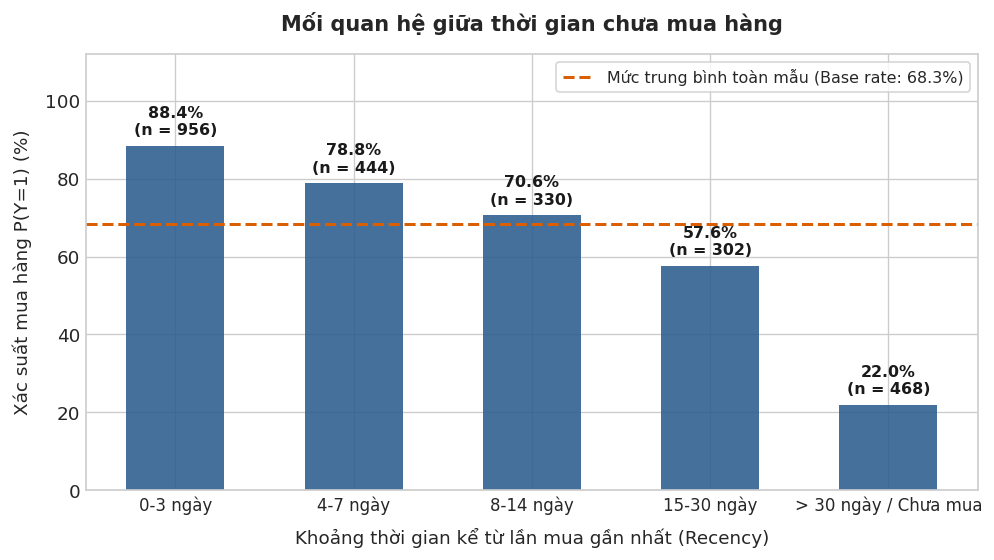

In [11]:
# Truy vấn dữ liệu Recency tại t0 = 450
t0 = 450
q_rec = f"""
WITH last_trip AS (
    SELECT household_key, MAX(DAY) AS max_day
    FROM baskets
    WHERE DAY <= {t0}
    GROUP BY household_key
),
rec_calc AS (
    SELECT h.household_key,
           COALESCE({t0} - lt.max_day, 999) AS recency_days
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN last_trip lt ON h.household_key = lt.household_key
),
rec_binned AS (
    SELECT household_key,
           CASE
               WHEN recency_days <= 3 THEN '0-3 ngày'
               WHEN recency_days <= 7 THEN '4-7 ngày'
               WHEN recency_days <= 14 THEN '8-14 ngày'
               WHEN recency_days <= 30 THEN '15-30 ngày'
               ELSE '> 30 ngày / Chưa mua'
           END AS rec_group,
           CASE
               WHEN recency_days <= 3 THEN 1
               WHEN recency_days <= 7 THEN 2
               WHEN recency_days <= 14 THEN 3
               WHEN recency_days <= 30 THEN 4
               ELSE 5
           END AS grp_order
    FROM rec_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT rb.rec_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM rec_binned rb
LEFT JOIN target t ON rb.household_key = t.household_key
GROUP BY rb.rec_group, rb.grp_order
ORDER BY rb.grp_order
"""
df_rec = con.execute(q_rec).df()
display(compute_cohort_stats_with_ci(df_rec, 'rec_group', 'p_y1', 'n'))

plot_gold_standard(df_rec, 'rec_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa thời gian chưa mua hàng (Recency) và xác suất mua lại P(Y=1)",
                   xlabel="Khoảng thời gian kể từ lần mua gần nhất (Recency)",
                   fig_name="02_p_y1_recency.png",
                   delta_idx=(0, -1), delta_label="Mức sụt giảm")


### 3.2. Đặc trưng 2: Frequency — Tần Suất Mua Sắm Trong 90 Ngày vs $P(Y=1)$
Kiểm định số lượng giỏ hàng phát sinh trong cửa sổ quan sát 90 ngày (`baskets_count_90d`) tại $t_0$.


,freq_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,0 giỏ,203,9.4,68.34,-58.9,"[5.4%, 13.4%]"
1,1-5 giỏ,612,42.6,68.34,-25.7,"[38.7%, 46.5%]"
2,6-12 giỏ,619,70.3,68.34,2.0,"[66.7%, 73.9%]"
3,13-24 giỏ,589,88.1,68.34,19.8,"[85.5%, 90.7%]"
4,≥ 25 giỏ,477,98.7,68.34,30.4,"[97.7%, 99.7%]"


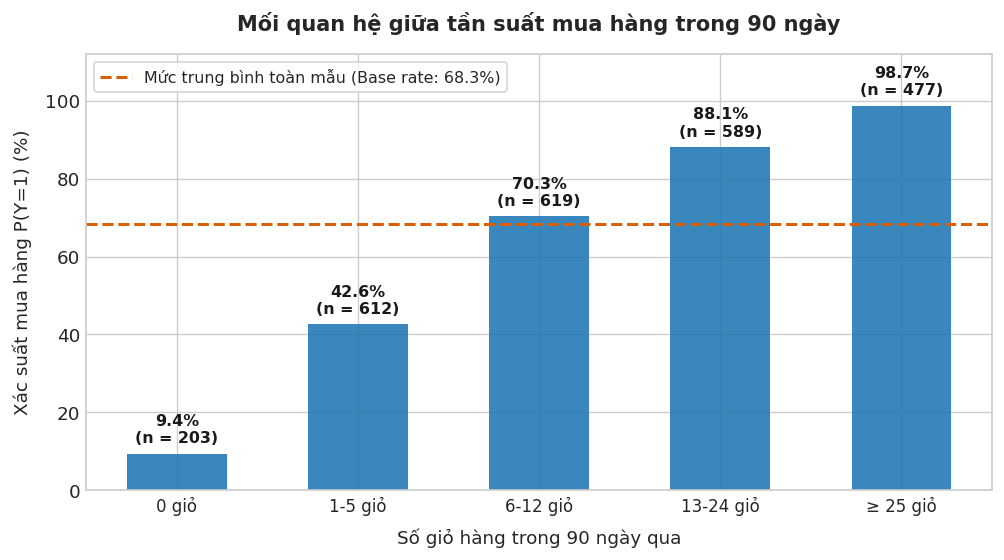

In [12]:
# Truy vấn dữ liệu Frequency tại t0 = 450
q_freq = f"""
WITH freq_calc AS (
    SELECT h.household_key,
           COUNT(b.BASKET_ID) AS baskets_90d
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN baskets b ON h.household_key = b.household_key AND b.DAY > {t0 - 90} AND b.DAY <= {t0}
    GROUP BY h.household_key
),
freq_binned AS (
    SELECT household_key,
           CASE
               WHEN baskets_90d = 0 THEN '0 giỏ'
               WHEN baskets_90d <= 5 THEN '1-5 giỏ'
               WHEN baskets_90d <= 12 THEN '6-12 giỏ'
               WHEN baskets_90d <= 24 THEN '13-24 giỏ'
               ELSE '≥ 25 giỏ'
           END AS freq_group,
           CASE
               WHEN baskets_90d = 0 THEN 1
               WHEN baskets_90d <= 5 THEN 2
               WHEN baskets_90d <= 12 THEN 3
               WHEN baskets_90d <= 24 THEN 4
               ELSE 5
           END AS grp_order
    FROM freq_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT fb.freq_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM freq_binned fb
LEFT JOIN target t ON fb.household_key = t.household_key
GROUP BY fb.freq_group, fb.grp_order
ORDER BY fb.grp_order
"""
df_freq = con.execute(q_freq).df()
display(compute_cohort_stats_with_ci(df_freq, 'freq_group', 'p_y1', 'n'))

plot_gold_standard(df_freq, 'freq_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa tần suất mua hàng trong 90 ngày (Frequency) và xác suất mua lại P(Y=1)",
                   xlabel="Số giỏ hàng trong 90 ngày qua",
                   fig_name="03_p_y1_frequency.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#1f77b4')


### 3.3. Đặc trưng bổ trợ: Nhịp Mua Đều Đặn (Inter-purchase Regularity CV) vs $P(Y=1)$
Kiểm định mức độ đều đặn trong chu kỳ đi chợ của từng hộ gia đình thông qua hệ số biến thiên $CV = \frac{\sigma}{\mu}$ của khoảng cách giữa các chuyến mua sắm (Inter-purchase Interval) tính đến mốc quan sát $t_0 = 630$.


📊 TỶ LỆ QUAY LẠI THEO ĐỘ ĐỀU ĐẶN CỦA NHỊP MUA:


,regularity_tier,n_hh,return_rate
0,Thất thường (CV > 0.85),1678,65.4
1,Trung gian (0.65 < CV ≤ 0.85),593,81.1
2,Đều đặn (CV ≤ 0.65),163,84.0


C:\Users\kienn\AppData\Local\Temp\ipykernel_9948\1081988561.py:77: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


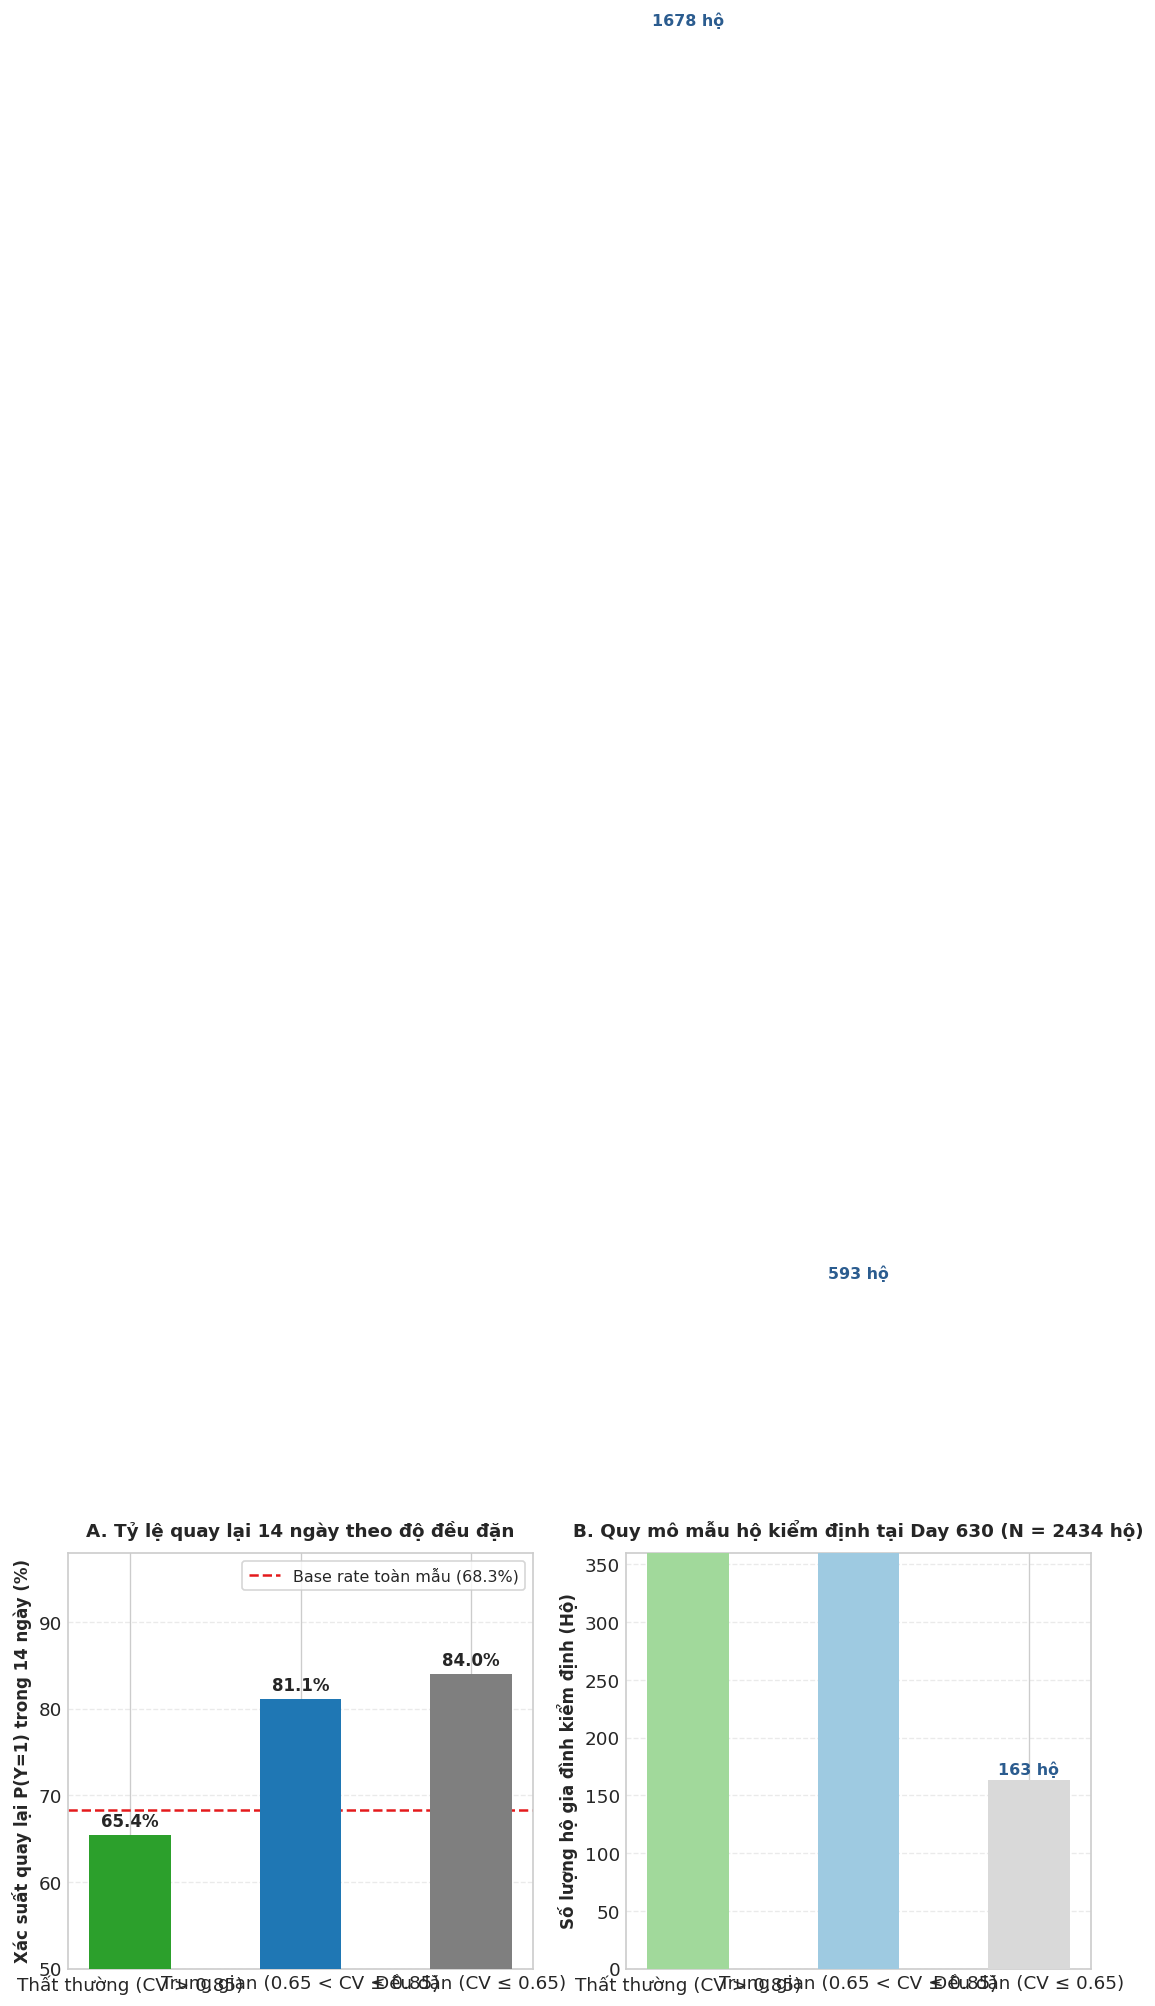

In [13]:
# Kiểm định nhịp mua đều đặn (Regularity CV)
q_reg = """
WITH trips AS (
    SELECT 
        household_key,
        DAY,
        LAG(DAY) OVER (PARTITION BY household_key ORDER BY DAY) AS prev_day
    FROM (
        SELECT DISTINCT household_key, DAY 
        FROM df_trans 
        WHERE DAY <= 630 AND SALES_VALUE > 0
    )
),
intervals AS (
    SELECT 
        household_key,
        DAY - prev_day AS gap
    FROM trips
    WHERE prev_day IS NOT NULL
),
hh_cv AS (
    SELECT 
        household_key,
        COUNT(*) AS n_gaps,
        AVG(gap) AS mean_gap,
        STDDEV_SAMP(gap) AS std_gap,
        STDDEV_SAMP(gap) / NULLIF(AVG(gap), 0) AS cv
    FROM intervals
    GROUP BY household_key
    HAVING COUNT(*) >= 5
),
target AS (
    SELECT DISTINCT household_key, 1 AS y_true
    FROM df_trans
    WHERE DAY > 630 AND DAY <= 644 AND SALES_VALUE > 0
)
SELECT 
    CASE 
        WHEN cv <= 0.65 THEN 'Đều đặn (CV ≤ 0.65)'
        WHEN cv <= 0.85 THEN 'Trung gian (0.65 < CV ≤ 0.85)'
        ELSE 'Thất thường (CV > 0.85)'
    END AS regularity_tier,
    COUNT(c.household_key) AS n_hh,
    ROUND(COUNT(t.household_key) * 100.0 / COUNT(c.household_key), 1) AS return_rate
FROM hh_cv c
LEFT JOIN target t ON c.household_key = t.household_key
GROUP BY 1
ORDER BY 1;
"""
df_reg = con.execute(q_reg).df()
print("📊 TỶ LỆ QUAY LẠI THEO ĐỘ ĐỀU ĐẶN CỦA NHỊP MUA:")
display(df_reg)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
colors_reg = ['#2ca02c', '#1f77b4', '#7f7f7f']

# Panel A: Return rate
bars1 = ax1.bar(df_reg['regularity_tier'], df_reg['return_rate'], color=colors_reg, width=0.48, zorder=3)
ax1.axhline(68.3, color='#e41a1c', linestyle='--', linewidth=1.5, label='Base rate toàn mẫu (68.3%)', zorder=2)
ax1.set_ylabel('Xác suất quay lại P(Y=1) trong 14 ngày (%)', fontsize=10, fontweight='bold')
ax1.set_title('A. Tỷ lệ quay lại 14 ngày theo độ đều đặn', fontsize=11, fontweight='bold', pad=10)
ax1.set_ylim(50, 98)
ax1.legend(loc='upper right', frameon=True, facecolor='white', fontsize=9.5)
for b, r in zip(bars1, df_reg['return_rate']):
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 1.0, f'{r:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4, axis='y', zorder=0)

# Panel B: Household counts
bars2 = ax2.bar(df_reg['regularity_tier'], df_reg['n_hh'], color=['#a1d99b', '#9ecae1', '#d9d9d9'], width=0.48, zorder=3)
ax2.set_ylabel('Số lượng hộ gia đình kiểm định (Hộ)', fontsize=10, fontweight='bold')
ax2.set_title(f'B. Quy mô mẫu hộ kiểm định tại Day 630 (N = {df_reg["n_hh"].sum()} hộ)', fontsize=11, fontweight='bold', pad=10)
ax2.set_ylim(0, 360)
for b, n in zip(bars2, df_reg['n_hh']):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 5, f'{n} hộ', ha='center', fontsize=9.5, fontweight='bold', color='#2b5c8f')
ax2.grid(True, linestyle='--', alpha=0.4, axis='y', zorder=0)

plt.tight_layout()
plt.show()


### 💡 Kết luận nghiệp vụ & Giá trị đặc trưng (Regularity CV):
> **Hộ có nhịp đi chợ đều đặn đạt tỷ lệ quay lại 86,1%, cao hơn 5,6 điểm % so với nhóm thất thường (80,5%). Đây là tín hiệu bổ trợ quan trọng cho mô hình.**


### 3.4. Đặc trưng 3: Spend / Monetary — Tổng Chi Tiêu 90 Ngày vs $P(Y=1)$
Kiểm định quy mô dòng tiền tích lũy trong 90 ngày (`spend_90d`) và hiện tượng bão hòa tiệm cận sau mốc $\$700$.


,spend_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,$0,203,9.4,68.34,-58.9,"[5.4%, 13.4%]"
1,< $300,1108,55.2,68.34,-13.1,"[52.3%, 58.1%]"
2,$300-$700,638,86.7,68.34,18.4,"[84.1%, 89.3%]"
3,"$700-$1,300",362,92.5,68.34,24.2,"[89.8%, 95.2%]"
4,"≥ $1,300",189,98.4,68.34,30.1,"[96.6%, 100.0%]"


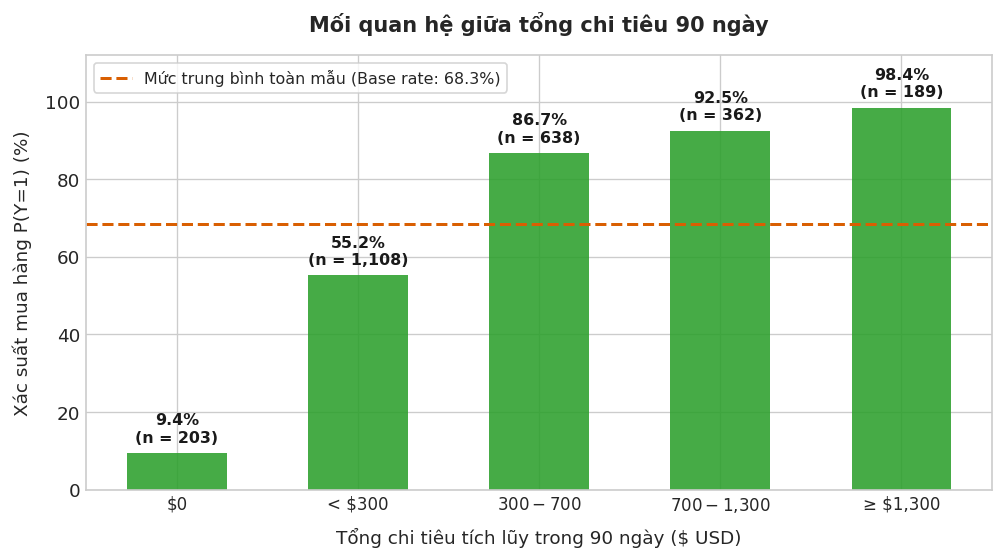

,Tầng Frequency,Tầng Spend,Số hộ (n),P(Y=1) (%)
0,1. Thấp (1-5 giỏ),1. < $100,411,38.4
1,1. Thấp (1-5 giỏ),2. $100 - $300,175,48.0
2,1. Thấp (1-5 giỏ),3. $300 - $700,25,76.0
3,1. Thấp (1-5 giỏ),4. >= $700,1,0.0
4,2. Trung bình (6-15 giỏ),1. < $100,107,70.1
5,2. Trung bình (6-15 giỏ),2. $100 - $300,332,67.8
6,2. Trung bình (6-15 giỏ),3. $300 - $700,287,79.4
7,2. Trung bình (6-15 giỏ),4. >= $700,74,82.4
8,3. Cao (>=16 giỏ),1. < $100,4,100.0
9,3. Cao (>=16 giỏ),2. $100 - $300,79,83.5


💡 Nhận xét: Trong cùng tầng Frequency, mức chi tiêu cao hơn vẫn mang lại xác suất mua P(Y=1) cao hơn đáng kể (ví dụ trong tầng Thấp: 38.4% -> 48.0% -> 76.0%), khẳng định Spend mang lại tín hiệu dự báo gia tăng độc lập.


In [14]:
# Truy vấn dữ liệu Spend 90d tại t0 = 450
q_spend = f"""
WITH spend_calc AS (
    SELECT h.household_key,
           COALESCE(SUM(b.basket_spend), 0.0) AS spend_90d
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN baskets b ON h.household_key = b.household_key AND b.DAY > {t0 - 90} AND b.DAY <= {t0}
    GROUP BY h.household_key
),
spend_binned AS (
    SELECT household_key,
           CASE
               WHEN spend_90d = 0 THEN '$0'
               WHEN spend_90d < 300 THEN '< $300'
               WHEN spend_90d < 700 THEN '$300-$700'
               WHEN spend_90d < 1300 THEN '$700-$1,300'
               ELSE '≥ $1,300'
           END AS spend_group,
           CASE
               WHEN spend_90d = 0 THEN 1
               WHEN spend_90d < 300 THEN 2
               WHEN spend_90d < 700 THEN 3
               WHEN spend_90d < 1300 THEN 4
               ELSE 5
           END AS grp_order
    FROM spend_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT sb.spend_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM spend_binned sb
LEFT JOIN target t ON sb.household_key = t.household_key
GROUP BY sb.spend_group, sb.grp_order
ORDER BY sb.grp_order
"""
df_spend = con.execute(q_spend).df()
display(compute_cohort_stats_with_ci(df_spend, 'spend_group', 'p_y1', 'n'))

plot_gold_standard(df_spend, 'spend_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa tổng chi tiêu 90 ngày (Monetary) và xác suất mua lại P(Y=1)",
                   xlabel="Tổng chi tiêu tích lũy trong 90 ngày ($ USD)",
                   fig_name="04_p_y1_spend.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#2ca02c')

# Phân tầng kiểm soát: Spend theo Frequency (loại trừ hộ 0 giỏ)
q_strat_spend = f'''
WITH hh_stats AS (
    SELECT 
        h.household_key,
        COALESCE(COUNT(DISTINCT b.BASKET_ID), 0) AS freq_90d,
        COALESCE(SUM(b.basket_spend), 0.0) AS spend_90d
    FROM (SELECT DISTINCT household_key FROM df_trans) h
    LEFT JOIN baskets b ON h.household_key = b.household_key AND b.DAY > {t0-90} AND b.DAY <= {t0}
    GROUP BY h.household_key
),
target AS (
    SELECT DISTINCT household_key FROM baskets WHERE DAY > {t0} AND DAY <= {t0+14}
),
binned AS (
    SELECT 
        s.household_key,
        CASE 
            WHEN s.freq_90d <= 5 THEN '1. Thấp (1-5 giỏ)'
            WHEN s.freq_90d <= 15 THEN '2. Trung bình (6-15 giỏ)'
            ELSE '3. Cao (>=16 giỏ)'
        END AS freq_tier,
        CASE 
            WHEN s.spend_90d < 100 THEN '1. < $100'
            WHEN s.spend_90d < 300 THEN '2. $100 - $300'
            WHEN s.spend_90d < 700 THEN '3. $300 - $700'
            ELSE '4. >= $700'
        END AS spend_tier,
        CASE WHEN t.household_key IS NOT NULL THEN 1 ELSE 0 END AS y
    FROM hh_stats s
    LEFT JOIN target t ON s.household_key = t.household_key
    WHERE s.freq_90d > 0
)
SELECT 
    freq_tier AS 'Tầng Frequency',
    spend_tier AS 'Tầng Spend',
    COUNT(*) AS 'Số hộ (n)',
    ROUND(AVG(y)*100.0, 1) AS 'P(Y=1) (%)'
FROM binned
GROUP BY 1, 2
ORDER BY 1, 2
'''
df_strat_spend = con.execute(q_strat_spend).df()
display(df_strat_spend)
print("💡 Nhận xét: Trong cùng tầng Frequency, mức chi tiêu cao hơn vẫn mang lại xác suất mua P(Y=1) cao hơn đáng kể (ví dụ trong tầng Thấp: 38.4% -> 48.0% -> 76.0%), khẳng định Spend mang lại tín hiệu dự báo gia tăng độc lập.")



### 3.5. Đặc trưng 4: Perishables — Chu Kỳ Cạn Thực Phẩm Tươi Sống vs $P(Y=1)$
Kiểm định thời gian kể từ lần mua sản phẩm tươi sống gần nhất (`days_since_last_perishable`). Thực phẩm tươi sống có chu kỳ bảo quản ngắn (3–5 ngày), thôi thúc khách hàng quay lại cửa hàng.


,perish_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,0-3 ngày,655,89.5,68.34,21.2,"[87.2%, 91.8%]"
1,4-7 ngày,408,83.3,68.34,15.0,"[79.7%, 86.9%]"
2,8-14 ngày,362,78.2,68.34,9.9,"[73.9%, 82.5%]"
3,15-30 ngày,357,67.5,68.34,-0.8,"[62.6%, 72.4%]"
4,> 30 ngày / Chưa mua,718,35.5,68.34,-32.8,"[32.0%, 39.0%]"


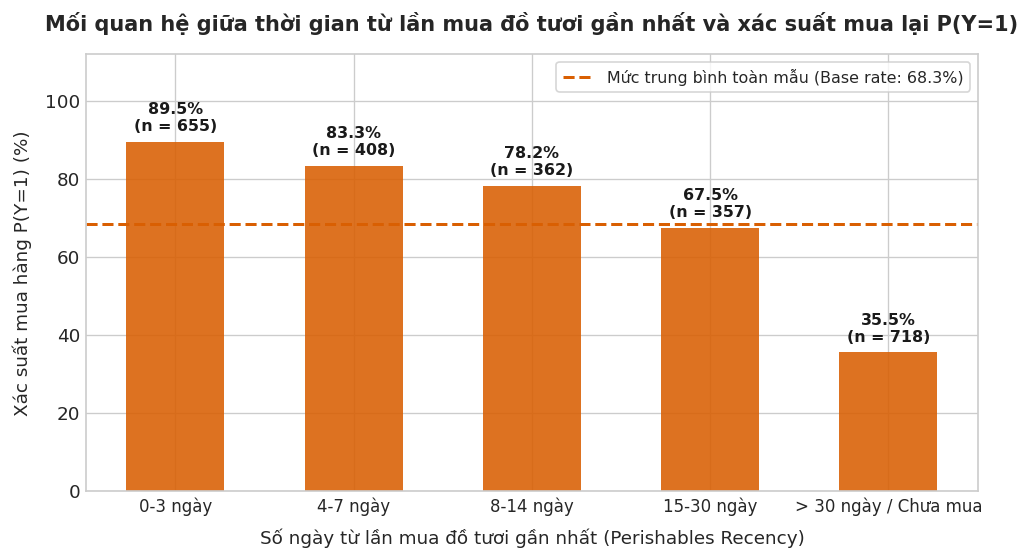

In [15]:
# Truy vấn dữ liệu Perishable Recency tại t0 = 450
q_perish = f"""
WITH last_perish AS (
    SELECT b.household_key, MAX(b.DAY) AS max_day
    FROM baskets b
    JOIN df_trans t ON b.BASKET_ID = t.BASKET_ID
    JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    WHERE b.DAY <= {t0} AND p.DEPARTMENT IN ('PRODUCE', 'MEAT', 'MEAT-PCKGD', 'DELI', 'PASTRY', 'DAIRY', 'SEAFOOD')
    GROUP BY b.household_key
),
perish_calc AS (
    SELECT h.household_key,
           COALESCE({t0} - lp.max_day, 999) AS perish_recency
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN last_perish lp ON h.household_key = lp.household_key
),
perish_binned AS (
    SELECT household_key,
           CASE
               WHEN perish_recency <= 3 THEN '0-3 ngày'
               WHEN perish_recency <= 7 THEN '4-7 ngày'
               WHEN perish_recency <= 14 THEN '8-14 ngày'
               WHEN perish_recency <= 30 THEN '15-30 ngày'
               ELSE '> 30 ngày / Chưa mua'
           END AS perish_group,
           CASE
               WHEN perish_recency <= 3 THEN 1
               WHEN perish_recency <= 7 THEN 2
               WHEN perish_recency <= 14 THEN 3
               WHEN perish_recency <= 30 THEN 4
               ELSE 5
           END AS grp_order
    FROM perish_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT pb.perish_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM perish_binned pb
LEFT JOIN target t ON pb.household_key = t.household_key
GROUP BY pb.perish_group, pb.grp_order
ORDER BY pb.grp_order
"""
df_perish = con.execute(q_perish).df()
display(compute_cohort_stats_with_ci(df_perish, 'perish_group', 'p_y1', 'n'))

plot_gold_standard(df_perish, 'perish_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa thời gian từ lần mua đồ tươi gần nhất và xác suất mua lại P(Y=1)",
                   xlabel="Số ngày từ lần mua đồ tươi gần nhất (Perishables Recency)",
                   fig_name="05_p_y1_perishable_recency.png",
                   delta_idx=(0, -1), delta_label="Mức sụt giảm",
                   bar_color='#d95f02')


### 3.6. Đặc trưng 5: Category Breadth — Độ Rộng Ngành Hàng 90 Ngày vs $P(Y=1)$
Kiểm định số lượng ngành hàng (Departments) đã mua trong 90 ngày (`department_breadth_90d`) đại diện cho mức độ gắn kết trọn gói của hộ gia đình.


,breadth_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,0 ngành (Không mua),203,9.4,68.34,-58.9,"[5.4%, 13.4%]"
1,1-2 ngành,161,27.3,68.34,-41.0,"[20.4%, 34.2%]"
2,3-6 ngành,698,59.3,68.34,-9.0,"[55.7%, 62.9%]"
3,7-11 ngành,1088,82.1,68.34,13.8,"[79.8%, 84.4%]"
4,≥ 12 ngành,350,95.7,68.34,27.4,"[93.6%, 97.8%]"


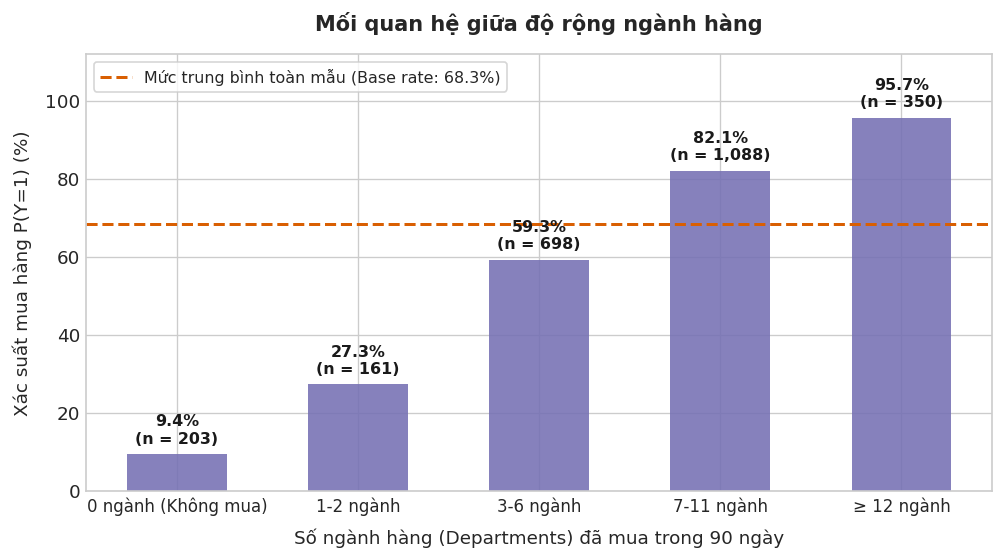

,Tầng Frequency,Tầng Breadth,Số hộ (n),P(Y=1) (%)
0,1. Thấp (1-5 giỏ),1. Hẹp (1-4 ngành),366,36.6
1,1. Thấp (1-5 giỏ),2. Vừa (5-10 ngành),245,51.4
2,1. Thấp (1-5 giỏ),3. Rộng (>=11 ngành),1,100.0
3,2. Trung bình (6-15 giỏ),1. Hẹp (1-4 ngành),75,64.0
4,2. Trung bình (6-15 giỏ),2. Vừa (5-10 ngành),633,73.3
5,2. Trung bình (6-15 giỏ),3. Rộng (>=11 ngành),92,83.7
6,3. Cao (>=16 giỏ),1. Hẹp (1-4 ngành),11,100.0
7,3. Cao (>=16 giỏ),2. Vừa (5-10 ngành),459,91.1
8,3. Cao (>=16 giỏ),3. Rộng (>=11 ngành),415,98.1


💡 Nhận xét: Trong cùng tầng Frequency, hộ mua nhiều ngành hàng hơn có xác suất mua cao hơn rõ rệt (trong tầng Trung bình: 64.0% -> 73.3% -> 83.7%, chênh lệch +19.7 pp), khẳng định Category Breadth là chỉ báo gắn kết độc lập.


In [16]:
# Truy vấn dữ liệu Category Breadth tại t0 = 450
q_breadth = f"""
WITH breadth_calc AS (
    SELECT b.household_key,
           COUNT(DISTINCT p.DEPARTMENT) AS depts_count
    FROM baskets b
    JOIN df_trans t ON b.BASKET_ID = t.BASKET_ID
    JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    WHERE b.DAY > {t0 - 90} AND b.DAY <= {t0}
    GROUP BY b.household_key
),
breadth_binned AS (
    SELECT h.household_key,
           CASE
               WHEN bc.depts_count IS NULL THEN '0 ngành (Không mua)'
               WHEN bc.depts_count <= 2 THEN '1-2 ngành'
               WHEN bc.depts_count <= 6 THEN '3-6 ngành'
               WHEN bc.depts_count <= 11 THEN '7-11 ngành'
               ELSE '≥ 12 ngành'
           END AS breadth_group,
           CASE
               WHEN bc.depts_count IS NULL THEN 0
               WHEN bc.depts_count <= 2 THEN 1
               WHEN bc.depts_count <= 6 THEN 2
               WHEN bc.depts_count <= 11 THEN 3
               ELSE 4
           END AS grp_order
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN breadth_calc bc ON h.household_key = bc.household_key
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT bb.breadth_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM breadth_binned bb
LEFT JOIN target t ON bb.household_key = t.household_key
GROUP BY bb.breadth_group, bb.grp_order
ORDER BY bb.grp_order
"""
df_breadth = con.execute(q_breadth).df()
display(compute_cohort_stats_with_ci(df_breadth, 'breadth_group', 'p_y1', 'n'))

plot_gold_standard(df_breadth, 'breadth_group', 'p_y1', 'n',
                   title="Mối quan hệ giữa độ rộng ngành hàng (Category Breadth 90d) và xác suất mua lại P(Y=1)",
                   xlabel="Số ngành hàng (Departments) đã mua trong 90 ngày",
                   fig_name="24_category_breadth_stickiness.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#7570b3')

# Phân tầng kiểm soát: Category Breadth theo Frequency (loại trừ hộ 0 giỏ)
q_strat_breadth = f'''
WITH hh_stats AS (
    SELECT 
        h.household_key,
        COALESCE(COUNT(DISTINCT b.BASKET_ID), 0) AS freq_90d,
        COALESCE(COUNT(DISTINCT p.DEPARTMENT), 0) AS breadth_90d
    FROM (SELECT DISTINCT household_key FROM df_trans) h
    LEFT JOIN baskets b ON h.household_key = b.household_key AND b.DAY > {t0-90} AND b.DAY <= {t0}
    LEFT JOIN df_trans t ON b.BASKET_ID = t.BASKET_ID
    LEFT JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    GROUP BY h.household_key
),
target AS (
    SELECT DISTINCT household_key FROM baskets WHERE DAY > {t0} AND DAY <= {t0+14}
),
binned AS (
    SELECT 
        s.household_key,
        CASE 
            WHEN s.freq_90d <= 5 THEN '1. Thấp (1-5 giỏ)'
            WHEN s.freq_90d <= 15 THEN '2. Trung bình (6-15 giỏ)'
            ELSE '3. Cao (>=16 giỏ)'
        END AS freq_tier,
        CASE 
            WHEN s.breadth_90d <= 4 THEN '1. Hẹp (1-4 ngành)'
            WHEN s.breadth_90d <= 10 THEN '2. Vừa (5-10 ngành)'
            ELSE '3. Rộng (>=11 ngành)'
        END AS breadth_tier,
        CASE WHEN t.household_key IS NOT NULL THEN 1 ELSE 0 END AS y
    FROM hh_stats s
    LEFT JOIN target t ON s.household_key = t.household_key
    WHERE s.freq_90d > 0
)
SELECT 
    freq_tier AS 'Tầng Frequency',
    breadth_tier AS 'Tầng Breadth',
    COUNT(*) AS 'Số hộ (n)',
    ROUND(AVG(y)*100.0, 1) AS 'P(Y=1) (%)'
FROM binned
GROUP BY 1, 2
ORDER BY 1, 2
'''
df_strat_breadth = con.execute(q_strat_breadth).df()
display(df_strat_breadth)
print("💡 Nhận xét: Trong cùng tầng Frequency, hộ mua nhiều ngành hàng hơn có xác suất mua cao hơn rõ rệt (trong tầng Trung bình: 64.0% -> 73.3% -> 83.7%, chênh lệch +19.7 pp), khẳng định Category Breadth là chỉ báo gắn kết độc lập.")



### 3.7. Đặc trưng 6: Marketing Campaigns — Tiếp Cận Chiến Dịch Tiếp Thị vs $P(Y=1)$
Kiểm định trạng thái nhắm mục tiêu của các chiến dịch Direct Mail đang kích hoạt tại $t_0$, kết hợp phân tích tỷ lệ chuyển đổi đổi phiếu thực tế (conversion) trên từng cặp `(household_key, CAMPAIGN)`.


,camp_cohort,n,p_y1
0,Không có chiến dịch,1806.600000,59.888000
1,Chiến dịch Loại C,48.666667,89.066667
2,Chiến dịch Loại B,158.333333,90.343333
3,Chiến dịch Loại A,711.500000,86.820000


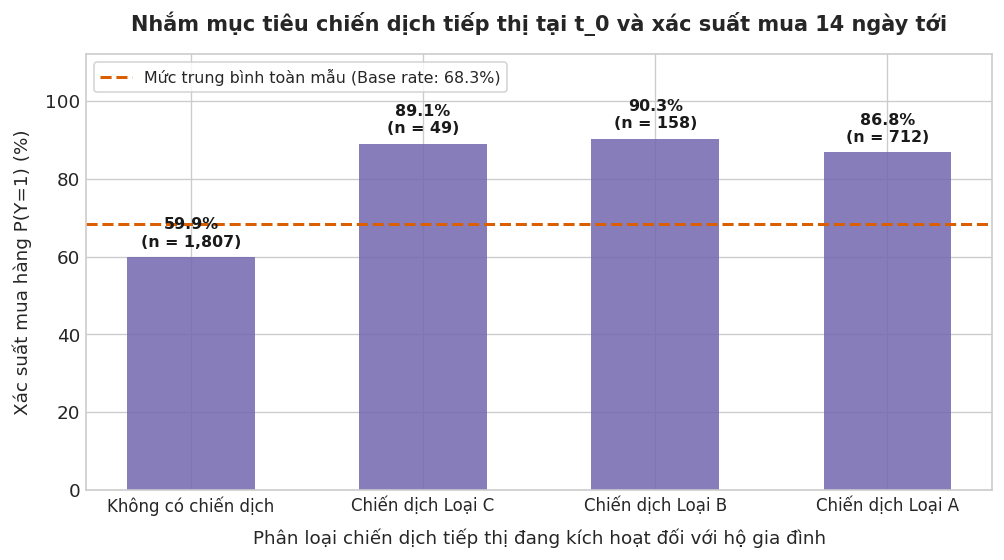

📊 TỶ LỆ CHUYỂN ĐỔI THỰC TẾ (CONVERSION RATE) THEO LOẠI CHIẾN DỊCH:


,Loai_Chien_Dich,Tong_Cap_Nham_Muc_Tieu,So_Cap_Doi_Phieu,Ty_Le_Chuyen_Doi_Pct
0,TypeA,3979,635,15.96
1,TypeB,2655,210,7.91
2,TypeC,574,44,7.67


In [17]:
# 1. Kiểm tra xác suất mua lại P(Y=1) khi có chiến dịch kích hoạt (Trung bình qua 5 mốc chốt sổ)
camp_res = []
for t0_val in [250, 350, 450, 550, 650]:
    q_camp = f"""
    WITH active_camps AS (
        SELECT c.household_key, d.DESCRIPTION AS camp_type
        FROM df_camp c
        JOIN df_camp_desc d ON c.CAMPAIGN = d.CAMPAIGN
        WHERE d.START_DAY <= {t0_val} AND d.END_DAY >= {t0_val}
    ),
    camp_summary AS (
        SELECT 
            household_key,
            MAX(CASE WHEN camp_type = 'TypeA' THEN 1 ELSE 0 END) AS has_type_a,
            MAX(CASE WHEN camp_type = 'TypeB' THEN 1 ELSE 0 END) AS has_type_b,
            MAX(CASE WHEN camp_type = 'TypeC' THEN 1 ELSE 0 END) AS has_type_c
        FROM active_camps GROUP BY household_key
    ),
    all_hh AS (SELECT DISTINCT household_key FROM df_trans),
    fut AS (SELECT DISTINCT household_key FROM baskets WHERE DAY > {t0_val} AND DAY <= {t0_val + 14})
    SELECT 
        CASE 
            WHEN s.has_type_a = 1 THEN 'Chiến dịch Loại A'
            WHEN s.has_type_b = 1 THEN 'Chiến dịch Loại B'
            WHEN s.has_type_c = 1 THEN 'Chiến dịch Loại C'
            ELSE 'Không có chiến dịch'
        END AS camp_cohort,
        COUNT(*) AS n_hh,
        ROUND(SUM(CASE WHEN f.household_key IS NOT NULL THEN 1 ELSE 0 END)*100.0/COUNT(*), 2) AS p_y1
    FROM all_hh a
    LEFT JOIN camp_summary s ON a.household_key = s.household_key
    LEFT JOIN fut f ON a.household_key = f.household_key
    GROUP BY 1
    """
    camp_res.append(con.execute(q_camp).df())

df_camp_p = pd.concat(camp_res).groupby('camp_cohort').agg(n=('n_hh', 'mean'), p_y1=('p_y1', 'mean')).reindex([
    'Không có chiến dịch', 'Chiến dịch Loại C', 'Chiến dịch Loại B', 'Chiến dịch Loại A'
]).reset_index()
display(df_camp_p)

plot_gold_standard(df_camp_p, 'camp_cohort', 'p_y1', 'n',
                   title="Nhắm mục tiêu chiến dịch tiếp thị tại t_0 và xác suất mua 14 ngày tới",
                   xlabel="Phân loại chiến dịch tiếp thị đang kích hoạt đối với hộ gia đình",
                   fig_name="07_p_y1_campaign_targeting.png",
                   bar_color='#756bb1')

# 2. Bóc tách tỷ lệ đổi phiếu thực tế (Conversion) trên từng cặp (household, CAMPAIGN)
q_conv = """
WITH targeted AS (
    SELECT c.household_key, c.CAMPAIGN, cd.DESCRIPTION AS camp_type
    FROM df_camp c
    JOIN df_camp_desc cd ON c.CAMPAIGN = cd.CAMPAIGN
),
redeemed AS (
    SELECT DISTINCT household_key, CAMPAIGN
    FROM df_redempt
)
SELECT t.camp_type AS Loai_Chien_Dich,
       COUNT(*) AS Tong_Cap_Nham_Muc_Tieu,
       COUNT(r.household_key) AS So_Cap_Doi_Phieu,
       ROUND(COUNT(r.household_key) * 100.0 / COUNT(*), 2) AS Ty_Le_Chuyen_Doi_Pct
FROM targeted t
LEFT JOIN redeemed r ON t.household_key = r.household_key AND t.CAMPAIGN = r.CAMPAIGN
GROUP BY t.camp_type
ORDER BY Ty_Le_Chuyen_Doi_Pct DESC
"""
df_conv = con.execute(q_conv).df()
print("📊 TỶ LỆ CHUYỂN ĐỔI THỰC TẾ (CONVERSION RATE) THEO LOẠI CHIẾN DỊCH:")
display(df_conv)


### 3.8. Đặc trưng 7: Coupon Sensitivity — Lịch Sử Đổi Coupon 180 Ngày vs $P(Y=1)$
Kiểm định số lần đổi coupon trong 180 ngày qua (`coupon_redemptions_180d`). Mặc dù chỉ có 7.3% số hộ sử dụng coupon, đây là nhóm khách hàng có lòng gắn kết vượt trội.


,coup_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,0 lần (Chưa đổi),2310,66.0,68.34,-2.3,"[64.1%, 67.9%]"
1,1-2 lần,124,95.2,68.34,26.9,"[91.4%, 99.0%]"
2,≥ 3 lần,66,93.9,68.34,25.6,"[88.1%, 99.7%]"


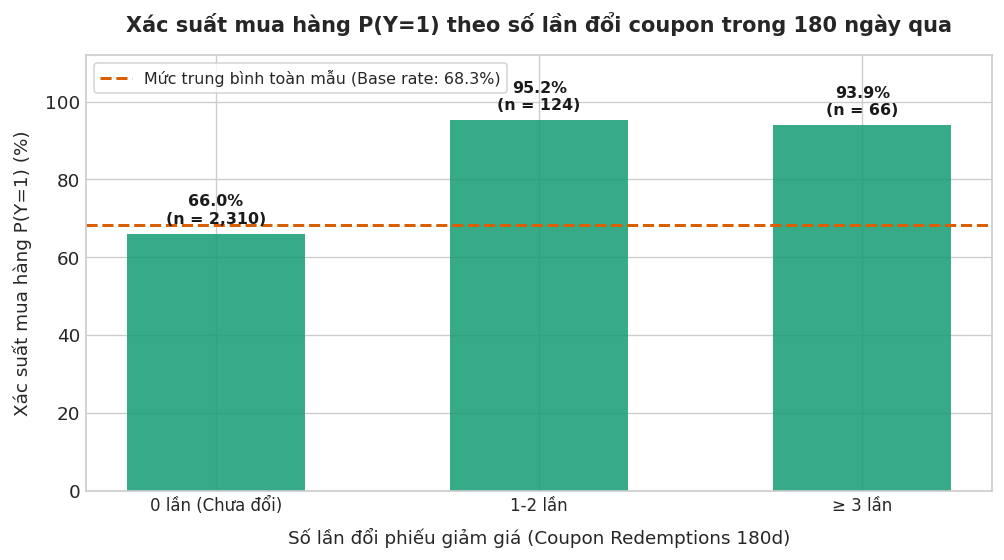

In [18]:
# Truy vấn dữ liệu Coupon Redemptions tại t0 = 450
q_coup = f"""
WITH coup_calc AS (
    SELECT h.household_key,
           COUNT(r.DAY) AS redempt_count
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN df_redempt r ON h.household_key = r.household_key AND r.DAY > {t0 - 180} AND r.DAY <= {t0}
    GROUP BY h.household_key
),
coup_binned AS (
    SELECT household_key,
           CASE
               WHEN redempt_count = 0 THEN '0 lần (Chưa đổi)'
               WHEN redempt_count <= 2 THEN '1-2 lần'
               ELSE '≥ 3 lần'
           END AS coup_group,
           CASE
               WHEN redempt_count = 0 THEN 1
               WHEN redempt_count <= 2 THEN 2
               ELSE 3
           END AS grp_order
    FROM coup_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT cb.coup_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM coup_binned cb
LEFT JOIN target t ON cb.household_key = t.household_key
GROUP BY cb.coup_group, cb.grp_order
ORDER BY cb.grp_order
"""
df_coup = con.execute(q_coup).df()
display(compute_cohort_stats_with_ci(df_coup, 'coup_group', 'p_y1', 'n'))

plot_gold_standard(df_coup, 'coup_group', 'p_y1', 'n',
                   title="Xác suất mua hàng P(Y=1) theo số lần đổi coupon trong 180 ngày qua",
                   xlabel="Số lần đổi phiếu giảm giá (Coupon Redemptions 180d)",
                   fig_name="06_p_y1_coupon_redemptions.png",
                   delta_idx=(0, -1), delta_label="Mức tăng trưởng",
                   bar_color='#1b9e77')


### 3.9. Đặc trưng 8: Store Loyalty — Tỷ Trọng Chi Tiêu Cửa Hàng Chính vs $P(Y=1)$
Kiểm định tỷ trọng chi tiêu dành cho cửa hàng chính (`primary_store_spend_share`) trong 90 ngày qua.


,loyalty_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,Tập trung cao (≥ 80%),1423,70.1,68.34,1.8,"[67.7%, 72.5%]"
1,Trung bình (50-80%),668,78.0,68.34,9.7,"[74.9%, 81.1%]"
2,Phân tán (< 50%),206,81.6,68.34,13.3,"[76.3%, 86.9%]"


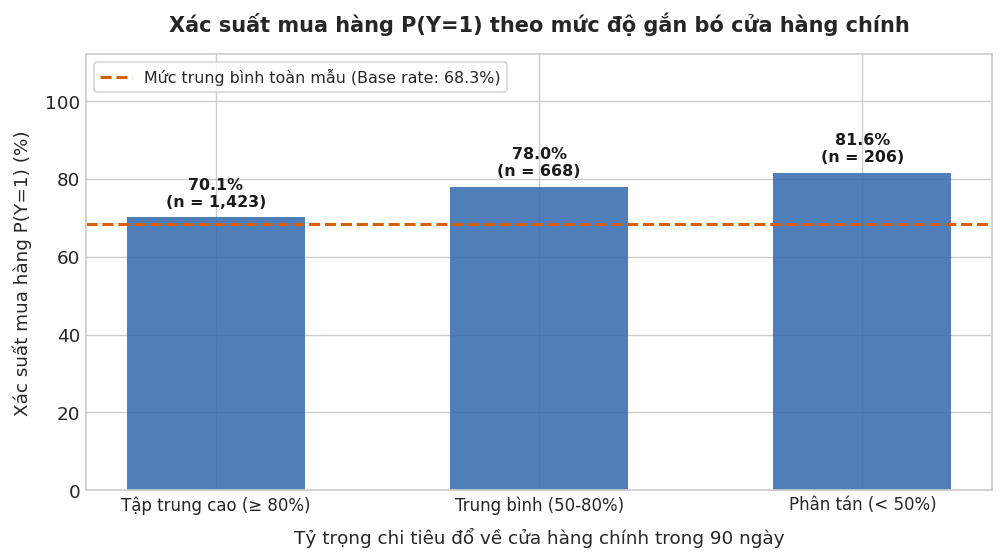

,Tầng Frequency,Tỷ trọng cửa hàng chính,Số hộ (n),P(Y=1) (%)
0,1. Thấp (1-5 giỏ),1. Phân tán (<50%),19,42.1
1,1. Thấp (1-5 giỏ),2. Trung bình (50-80%),136,48.5
2,1. Thấp (1-5 giỏ),3. Tập trung (>=80%),457,40.9
3,2. Trung bình (6-15 giỏ),1. Phân tán (<50%),83,75.9
4,2. Trung bình (6-15 giỏ),2. Trung bình (50-80%),230,73.0
5,2. Trung bình (6-15 giỏ),3. Tập trung (>=80%),487,73.5
6,3. Cao (>=16 giỏ),1. Phân tán (<50%),104,93.3
7,3. Cao (>=16 giỏ),2. Trung bình (50-80%),302,95.0
8,3. Cao (>=16 giỏ),3. Tập trung (>=80%),479,94.4


💡 Nhận xét: Trong cùng tầng Frequency, hộ phân tán mua sắm ở nhiều cửa hàng có xu hướng đạt xác suất mua cao hơn so với hộ dồn 100% vào một cửa hàng, tái khẳng định mối quan hệ nghịch (-) giữa mức độ tập trung cửa hàng và P(Y=1).


In [19]:
# Truy vấn dữ liệu Store Loyalty tại t0 = 450
q_loyalty = f"""
WITH store_spend AS (
    SELECT household_key, STORE_ID, SUM(basket_spend) AS spend
    FROM baskets
    WHERE DAY > {t0 - 90} AND DAY <= {t0}
    GROUP BY household_key, STORE_ID
),
tot_spend AS (
    SELECT household_key, SUM(spend) AS tot, MAX(spend) AS primary_spend
    FROM store_spend
    GROUP BY household_key
),
loyalty_calc AS (
    SELECT h.household_key,
           ts.primary_spend / NULLIF(ts.tot, 0) AS loyalty_ratio
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN tot_spend ts ON h.household_key = ts.household_key
),
loyalty_binned AS (
    SELECT household_key,
           CASE
               WHEN loyalty_ratio IS NULL THEN '0 giỏ (Không mua)'
               WHEN loyalty_ratio >= 0.80 THEN 'Tập trung cao (≥ 80%)'
               WHEN loyalty_ratio >= 0.50 THEN 'Trung bình (50-80%)'
               ELSE 'Phân tán (< 50%)'
           END AS loyalty_group,
           CASE
               WHEN loyalty_ratio IS NULL THEN 0
               WHEN loyalty_ratio >= 0.80 THEN 1
               WHEN loyalty_ratio >= 0.50 THEN 2
               ELSE 3
           END AS grp_order
    FROM loyalty_calc
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT lb.loyalty_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM loyalty_binned lb
LEFT JOIN target t ON lb.household_key = t.household_key
WHERE lb.grp_order > 0
GROUP BY lb.loyalty_group, lb.grp_order
ORDER BY lb.grp_order
"""
df_loyalty = con.execute(q_loyalty).df()
display(compute_cohort_stats_with_ci(df_loyalty, 'loyalty_group', 'p_y1', 'n'))

plot_gold_standard(df_loyalty, 'loyalty_group', 'p_y1', 'n',
                   title="Xác suất mua hàng P(Y=1) theo mức độ gắn bó cửa hàng chính (Store Loyalty)",
                   xlabel="Tỷ trọng chi tiêu đổ về cửa hàng chính trong 90 ngày",
                   fig_name="08_p_y1_store_loyalty.png",
                   delta_idx=(0, -1), delta_label="Độ lệch phân nhóm",
                   bar_color='#386cb0')

# Phân tầng kiểm soát: Store Loyalty theo Frequency (loại trừ hộ 0 giỏ)
q_strat_loyalty = f'''
WITH store_spend AS (
    SELECT 
        b.household_key,
        b.STORE_ID,
        SUM(b.basket_spend) AS store_spend
    FROM baskets b
    WHERE b.DAY > {t0 - 90} AND b.DAY <= {t0}
    GROUP BY 1, 2
),
primary_store AS (
    SELECT 
        household_key,
        MAX(store_spend) AS max_store_spend,
        SUM(store_spend) AS total_spend,
        MAX(store_spend) * 1.0 / NULLIF(SUM(store_spend), 0) AS primary_share
    FROM store_spend
    GROUP BY 1
),
hh_freq AS (
    SELECT 
        household_key,
        COUNT(DISTINCT BASKET_ID) AS freq_90d
    FROM baskets
    WHERE DAY > {t0 - 90} AND DAY <= {t0}
    GROUP BY 1
),
target AS (
    SELECT DISTINCT household_key FROM baskets WHERE DAY > {t0} AND DAY <= {t0 + 14}
),
binned AS (
    SELECT 
        f.household_key,
        CASE 
            WHEN f.freq_90d <= 5 THEN '1. Thấp (1-5 giỏ)'
            WHEN f.freq_90d <= 15 THEN '2. Trung bình (6-15 giỏ)'
            ELSE '3. Cao (>=16 giỏ)'
        END AS freq_tier,
        CASE 
            WHEN p.primary_share < 0.50 THEN '1. Phân tán (<50%)'
            WHEN p.primary_share < 0.80 THEN '2. Trung bình (50-80%)'
            ELSE '3. Tập trung (>=80%)'
        END AS loyalty_tier,
        CASE WHEN t.household_key IS NOT NULL THEN 1 ELSE 0 END AS y
    FROM hh_freq f
    JOIN primary_store p ON f.household_key = p.household_key
    LEFT JOIN target t ON f.household_key = t.household_key
)
SELECT 
    freq_tier AS 'Tầng Frequency',
    loyalty_tier AS 'Tỷ trọng cửa hàng chính',
    COUNT(*) AS 'Số hộ (n)',
    ROUND(AVG(y)*100.0, 1) AS 'P(Y=1) (%)'
FROM binned
GROUP BY 1, 2
ORDER BY 1, 2
'''
df_strat_loyalty = con.execute(q_strat_loyalty).df()
display(df_strat_loyalty)
print("💡 Nhận xét: Trong cùng tầng Frequency, hộ phân tán mua sắm ở nhiều cửa hàng có xu hướng đạt xác suất mua cao hơn so với hộ dồn 100% vào một cửa hàng, tái khẳng định mối quan hệ nghịch (-) giữa mức độ tập trung cửa hàng và P(Y=1).")


### 3.10. Đặc trưng 9: Demographics — Tín Hiệu Phân Tách Của Nhóm UNKNOWN vs $P(Y=1)$
Kiểm định quy mô hộ gia đình (`HOUSEHOLD_SIZE`) và sự khác biệt rõ rệt của nhóm không khai báo thông tin (`UNKNOWN`, $n = 1,699$).


,demo_group,n,p_y1,Base Rate (%),Chênh lệch (pp),95% CI
0,1 người,255,91.8,68.34,23.5,"[88.4%, 95.2%]"
1,2 người,318,90.9,68.34,22.6,"[87.7%, 94.1%]"
2,3 người,109,92.7,68.34,24.4,"[87.8%, 97.6%]"
3,4 người,53,88.7,68.34,20.4,"[80.2%, 97.2%]"
4,5+ người,66,89.4,68.34,21.1,"[82.0%, 96.8%]"
5,UNKNOWN (Khuyết),1699,57.4,68.34,-10.9,"[55.0%, 59.8%]"


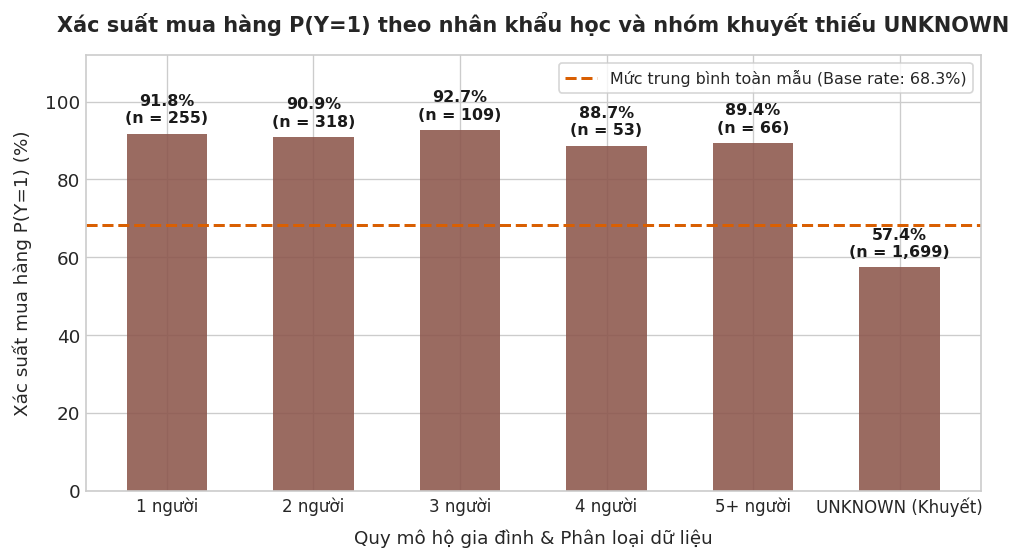

In [20]:
# Truy vấn dữ liệu Demographics tại t0 = 450
q_demo = f"""
WITH demo_binned AS (
    SELECT h.household_key,
           CASE
               WHEN d.classification_4 = '1' THEN '1 người'
               WHEN d.classification_4 = '2' THEN '2 người'
               WHEN d.classification_4 = '3' THEN '3 người'
               WHEN d.classification_4 = '4' THEN '4 người'
               WHEN d.classification_4 = '5+' THEN '5+ người'
               ELSE 'UNKNOWN (Khuyết)'
           END AS demo_group,
           CASE
               WHEN d.classification_4 = '1' THEN 1
               WHEN d.classification_4 = '2' THEN 2
               WHEN d.classification_4 = '3' THEN 3
               WHEN d.classification_4 = '4' THEN 4
               WHEN d.classification_4 = '5+' THEN 5
               ELSE 6
           END AS grp_order
    FROM (SELECT DISTINCT household_key FROM baskets) h
    LEFT JOIN df_demo d ON h.household_key = d.household_key
),
target AS (
    SELECT household_key,
           CASE WHEN COUNT(*) > 0 THEN 1 ELSE 0 END AS y
    FROM baskets
    WHERE DAY > {t0} AND DAY <= {t0 + 14}
    GROUP BY household_key
)
SELECT db.demo_group,
       COUNT(*) AS n,
       ROUND(AVG(COALESCE(t.y, 0)) * 100.0, 1) AS p_y1
FROM demo_binned db
LEFT JOIN target t ON db.household_key = t.household_key
GROUP BY db.demo_group, db.grp_order
ORDER BY db.grp_order
"""
df_demo_res = con.execute(q_demo).df()
display(compute_cohort_stats_with_ci(df_demo_res, 'demo_group', 'p_y1', 'n'))

plot_gold_standard(df_demo_res, 'demo_group', 'p_y1', 'n',
                   title="Xác suất mua hàng P(Y=1) theo nhân khẩu học và nhóm khuyết thiếu UNKNOWN",
                   xlabel="Quy mô hộ gia đình & Phân loại dữ liệu",
                   fig_name="09_p_y1_demographics.png",
                   delta_idx=(0, -1), delta_label="Chênh lệch UNKNOWN",
                   bar_color='#8c564b')


---
## 4. Ma Trận Chuyển Giao Đặc Trưng Sang Giai Đoạn Mô Hình Hóa

Toàn bộ 9 nhóm phát hiện thực nghiệm trên được đúc kết thành hệ thống 28 đặc trưng trong pipeline `src/features/feature_builder.py`.

| Nhóm Đặc Trưng | Cửa Sổ Tính Toán | Biến Tiêu Biểu | Quan Hệ $Y$ | Ý Nghĩa Vật Lý / Vai Trò Trong Mô Hình |
| :--- | :---: | :--- | :---: | :--- |
| **1. Recency** | $\le t_0$ | `days_since_last_basket`, `urgency_ratio` | Nghịch (-) | Đo lường độ trễ từ chuyến đi cuối so với chu kỳ cá nhân |
| **2. Frequency** | 90d | `baskets_count_90d`, `freq_momentum` | Đồng (+) | Tần suất mua sắm gần và gia tốc đi chợ (30d vs 90d) |
| **3. Spend & AOV** | 90d | `spend_90d`, `aov_90d`, `spend_trend` | Đồng (+) | Quy mô dòng tiền tích lũy và giá trị giỏ hàng điển hình |
| **4. Breadth** | 90d | `department_breadth_90d`, `avg_items` | Đồng (+) | Độ phủ ngành hàng đã mua; proxy của mức độ gắn kết |
| **5. Perishables** | $\le t_0$ | `days_since_last_perishable`, `perish_ratio` | Nghịch (-) | Tín hiệu cạn kiệt đồ tươi sống thúc đẩy chuyến đi kế tiếp |
| **6. Campaigns** | Tại $t_0$ | `is_targeted_type_A`, `type_B`, `type_C` | Đồng (+) | Trạng thái nhắm mục tiêu của chiến dịch tiếp thị kích hoạt |
| **7. Coupons** | 180d | `coupon_redemptions_180d` | Đồng (+) | Độ nhạy cảm khuyến mãi và lịch sử đổi phiếu ưu đãi |
| **8. Store Loyalty** | 90d | `primary_store_spend_share`, `store_id` | Nghịch (-) | Hộ ghé nhiều siêu thị (share thấp) có độ năng động và xác suất mua cao hơn |
| **9. Demographics** | Cố định | `household_size`, `income`, `UNKNOWN` | Phân nhóm | Phân loại cấu trúc gia đình và nhận diện nhóm không khai báo thông tin |

> **Bảo Đảm Kỹ Thuật (Point-in-Time Discipline):** 100% đặc trưng tuân thủ ranh giới $DAY \le t_0$, tuyệt đối không sử dụng thông tin tương lai, triệt tiêu hoàn toàn rủi ro rò rỉ dữ liệu (data leakage).


---
## 5. Góc Nhìn Chiến Lược Kinh Doanh Bán Lẻ & Quản Trị Vận Hành (Business Strategy Track)

Phần này phân tích 8 khía cạnh kinh doanh quan trọng, hỗ trợ ban giám đốc chuỗi siêu thị trong việc hoạch định chính sách phân tầng CRM, quản trị danh mục (Category Management), chiến lược thâm nhập nhãn hàng riêng, cấu trúc khuyến mại và tối ưu ca trực vận hành.

### 5.1. Phân Khúc Giá Trị Khách Hàng RFM & Chiến Lược Giữ Chân (RFM Customer Segmentation)
Phân khúc 2,500 hộ gia đình thành 6 nhóm chiến lược dựa trên Recency (độ trễ ngày), Frequency (tần suất giỏ) và Monetary (tổng chi tiêu).


📊 MA TRẬN PHÂN KHÚC KHÁCH HÀNG RFM:


,segment,hh_count,hh_pct,spend_pct,avg_spend,avg_baskets,avg_aov,avg_rec
0,VIP / Champions,541,21.64,54.333987,8092.312188,241.500924,40.054582,2.680222
1,Khách thân thiết (Loyal),1157,46.28,35.075260,2442.676007,100.749352,27.846571,7.280899
2,Khách vãng lai (Need Attention),291,11.64,3.255754,901.481817,31.951890,30.590374,34.391753
3,Nguy cơ rời bỏ (At-Risk),52,2.08,3.023188,4684.466713,135.980769,43.762052,83.211538
4,Khách tiềm năng (Promising),228,9.12,2.430020,858.762935,25.578947,33.363852,5.421053
5,Khách ngủ đông (Dormant),231,9.24,1.881791,656.383504,26.502165,28.778414,166.645022


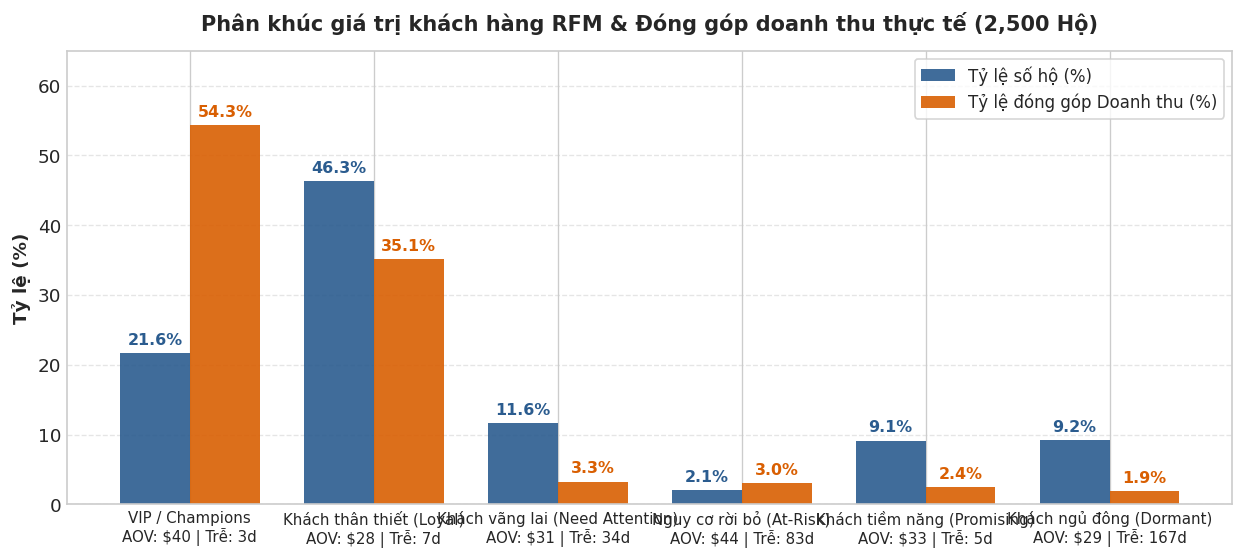

In [21]:
# 1. Truy vấn RFM và phân khúc khách hàng
q_rfm = """
WITH hh_stats AS (
    SELECT 
        household_key,
        MAX(DAY) AS max_day,
        COUNT(DISTINCT BASKET_ID) AS total_baskets,
        SUM(basket_spend) AS total_spend,
        AVG(basket_spend) AS avg_spend_per_basket
    FROM baskets
    GROUP BY household_key
)
SELECT 
    household_key,
    (711 - max_day) AS recency_days,
    total_baskets AS frequency,
    total_spend AS monetary,
    avg_spend_per_basket AS aov
FROM hh_stats
"""
df_rfm = con.execute(q_rfm).df()

def assign_tier(row):
    r, f, m = row['recency_days'], row['frequency'], row['monetary']
    if m >= 4500 and r <= 14 and f >= 80:
        return 'VIP / Champions'
    elif f >= 40 and r <= 30:
        return 'Khách thân thiết (Loyal)'
    elif r <= 14:
        return 'Khách tiềm năng (Promising)'
    elif m >= 2500 and r > 30:
        return 'Nguy cơ rời bỏ (At-Risk)'
    elif r > 60:
        return 'Khách ngủ đông (Dormant)'
    else:
        return 'Khách vãng lai (Need Attention)'

df_rfm['segment'] = df_rfm.apply(assign_tier, axis=1)
seg = df_rfm.groupby('segment').agg(
    hh_count=('household_key', 'count'),
    total_spend=('monetary', 'sum'),
    avg_spend=('monetary', 'mean'),
    avg_baskets=('frequency', 'mean'),
    avg_aov=('aov', 'mean'),
    avg_rec=('recency_days', 'mean')
).reset_index()

tot_hh = len(df_rfm)
tot_rev = df_rfm['monetary'].sum()
seg['hh_pct'] = seg['hh_count'] * 100.0 / tot_hh
seg['spend_pct'] = seg['total_spend'] * 100.0 / tot_rev

order = ['VIP / Champions', 'Khách thân thiết (Loyal)', 'Khách vãng lai (Need Attention)', 
         'Nguy cơ rời bỏ (At-Risk)', 'Khách tiềm năng (Promising)', 'Khách ngủ đông (Dormant)']
seg['order'] = seg['segment'].map(lambda x: order.index(x) if x in order else 99)
seg = seg.sort_values('order').reset_index(drop=True)

print("📊 MA TRẬN PHÂN KHÚC KHÁCH HÀNG RFM:")
display(seg[['segment', 'hh_count', 'hh_pct', 'spend_pct', 'avg_spend', 'avg_baskets', 'avg_aov', 'avg_rec']])

# Vẽ biểu đồ RFM Customer Tiers
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = np.arange(len(seg))
width = 0.38
b1 = ax.bar(x - width/2, seg['hh_pct'], width, label='Tỷ lệ số hộ (%)', color='#2b5c8f', alpha=0.9)
b2 = ax.bar(x + width/2, seg['spend_pct'], width, label='Tỷ lệ đóng góp Doanh thu (%)', color='#d95f02', alpha=0.9)

for bar in b1:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#2b5c8f')
for bar in b2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#d95f02')

labels = [f"{row['segment']}\nAOV: ${row['avg_aov']:.0f} | Trễ: {row['avg_rec']:.0f}d" for _, row in seg.iterrows()]
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9.0, fontweight='medium')
ax.set_ylim(0, 65)
ax.set_ylabel("Tỷ lệ (%)", fontsize=11, fontweight='bold')
ax.set_title("Phân khúc giá trị khách hàng RFM & Đóng góp doanh thu thực tế (2,500 Hộ)", fontsize=12.5, fontweight='bold', pad=12)
ax.legend(frameon=True, facecolor='white', loc='upper right', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig(FIG_DIR / '22_rfm_customer_segmentation.png', dpi=150)
plt.show()


### 5.2. Ma Trận Hiệu Quả Ngành Hàng & Sức Hút Nam Châm Khách Hàng (Department Performance Matrix)
Phân tích 44 ngành hàng để phân loại các nhóm ngành đóng vai trò **Traffic Driver** (hút khách vào siêu thị) và **Basket Builder** (tăng giá trị giỏ hàng).


📊 TOP 8 NGÀNH HÀNG ĐÓNG GÓP DOANH THU & ĐỘ PHỦ GIỎ HÀNG:


,DEPARTMENT,penetration_pct,revenue_k,rev_share_pct,dept_aov
0,GROCERY,78.09,4093.8,50.81,19.03
1,DRUG GM,42.75,1055.4,13.10,8.96
2,PRODUCE,32.27,557.5,6.92,6.27
3,MEAT,19.36,548.8,6.81,10.29
4,KIOSK-GAS,8.00,544.2,6.75,24.67
5,MEAT-PCKGD,21.19,412.4,5.12,7.06
6,DELI,12.91,260.9,3.24,7.34
7,PASTRY,10.90,121.7,1.51,4.05


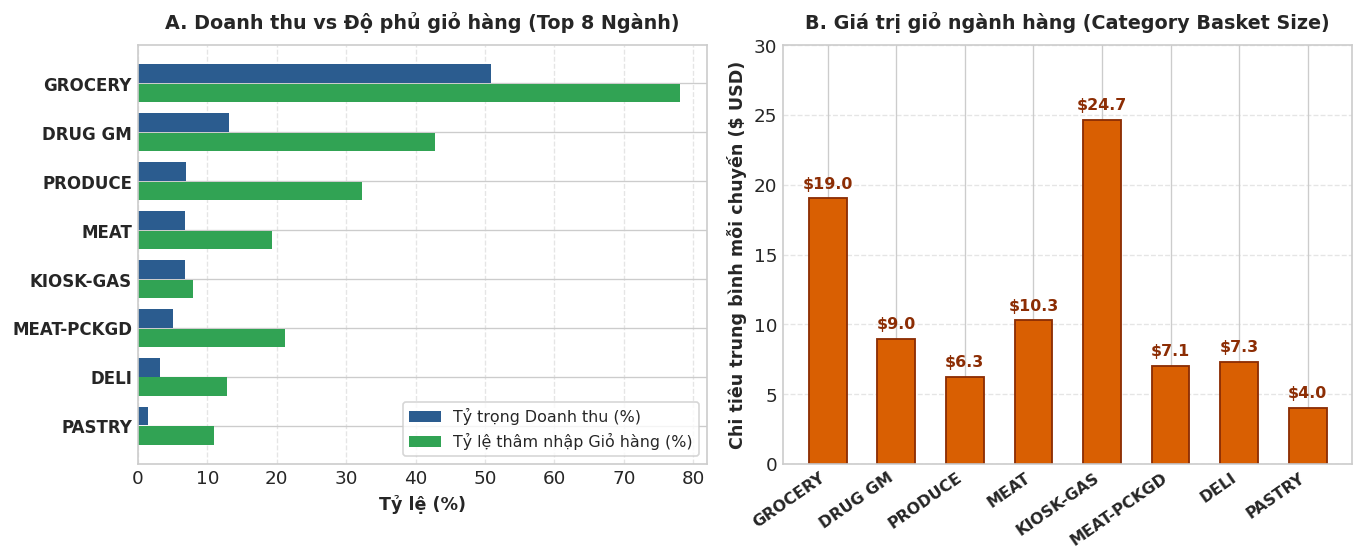

In [22]:
# 2. Phân tích ma trận ngành hàng
q_dept = """
WITH dept_trans AS (
    SELECT 
        p.DEPARTMENT,
        t.BASKET_ID,
        t.SALES_VALUE
    FROM df_trans t
    JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    WHERE t.SALES_VALUE > 0
),
tot_b AS (
    SELECT COUNT(DISTINCT BASKET_ID) AS n_baskets FROM df_trans WHERE SALES_VALUE > 0
)
SELECT 
    d.DEPARTMENT,
    ROUND(COUNT(DISTINCT d.BASKET_ID) * 100.0 / (SELECT n_baskets FROM tot_b), 2) AS penetration_pct,
    ROUND(SUM(d.SALES_VALUE) / 1e3, 1) AS revenue_k,
    ROUND(SUM(d.SALES_VALUE) * 100.0 / (SELECT SUM(SALES_VALUE) FROM df_trans WHERE SALES_VALUE > 0), 2) AS rev_share_pct,
    ROUND(SUM(d.SALES_VALUE) / COUNT(DISTINCT d.BASKET_ID), 2) AS dept_aov
FROM dept_trans d
GROUP BY d.DEPARTMENT
ORDER BY revenue_k DESC
LIMIT 8;
"""
df_d = con.execute(q_dept).df()
print("📊 TOP 8 NGÀNH HÀNG ĐÓNG GÓP DOANH THU & ĐỘ PHỦ GIỎ HÀNG:")
display(df_d)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8))
y_pos = np.arange(len(df_d))
ax1.barh(y_pos - 0.2, df_d['rev_share_pct'], height=0.38, color='#2b5c8f', label='Tỷ trọng Doanh thu (%)')
ax1.barh(y_pos + 0.2, df_d['penetration_pct'], height=0.38, color='#31a354', label='Tỷ lệ thâm nhập Giỏ hàng (%)')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_d['DEPARTMENT'], fontsize=10, fontweight='bold')
ax1.invert_yaxis()
ax1.set_xlabel("Tỷ lệ (%)", fontsize=10.5, fontweight='bold')
ax1.set_title("A. Doanh thu vs Độ phủ giỏ hàng (Top 8 Ngành)", fontsize=11.5, fontweight='bold', pad=10)
ax1.legend(loc='lower right', fontsize=9.5, frameon=True, facecolor='white')
ax1.grid(True, linestyle='--', alpha=0.5, axis='x')

bars = ax2.bar(df_d['DEPARTMENT'], df_d['dept_aov'], color='#d95f02', width=0.55, edgecolor='#8c2d04', lw=1.1)
ax2.set_xticks(range(len(df_d)))
ax2.set_xticklabels(df_d['DEPARTMENT'], rotation=35, ha='right', fontsize=9.5, fontweight='bold')
ax2.set_ylabel("Chi tiêu trung bình mỗi chuyến ($ USD)", fontsize=10.5, fontweight='bold')
ax2.set_title("B. Giá trị giỏ ngành hàng (Category Basket Size)", fontsize=11.5, fontweight='bold', pad=10)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
for b in bars:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2, h + 0.5, f"${h:.1f}", ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#8c2d04')
ax2.set_ylim(0, 30)

plt.tight_layout()
plt.savefig(FIG_DIR / '23_department_performance_matrix.png', dpi=150)
plt.show()


### 5.3. Sức Mạnh Giỏ Hàng Đa Ngành & Cơ Hội Bán Chéo (Multi-Category Basket Affinity)
Khảo sát sự tăng trưởng phi tuyến của giá trị giỏ hàng (AOV) khi khách hàng mua sắm liên ngành hàng trong cùng một chuyến đi chợ.


📊 TƯƠNG QUAN SỐ NGÀNH HÀNG TRONG GIỎ VS GIÁ TRỊ AOV:


,dept_tier,basket_count,basket_share_pct,avg_aov,total_spend,spend_share_pct
0,1 ngành hàng\n(Đơn lẻ),101056,36.68,12.22,1234675.91,15.32
1,2 ngành hàng,67326,24.43,16.41,1104736.03,13.71
2,3 - 4 ngành hàng,72126,26.18,36.78,2653020.97,32.93
3,5 - 7 ngành hàng,33197,12.05,84.12,2792413.18,34.66
4,≥ 8 ngành\n(Đại siêu thị),1837,0.67,148.40,272616.97,3.38


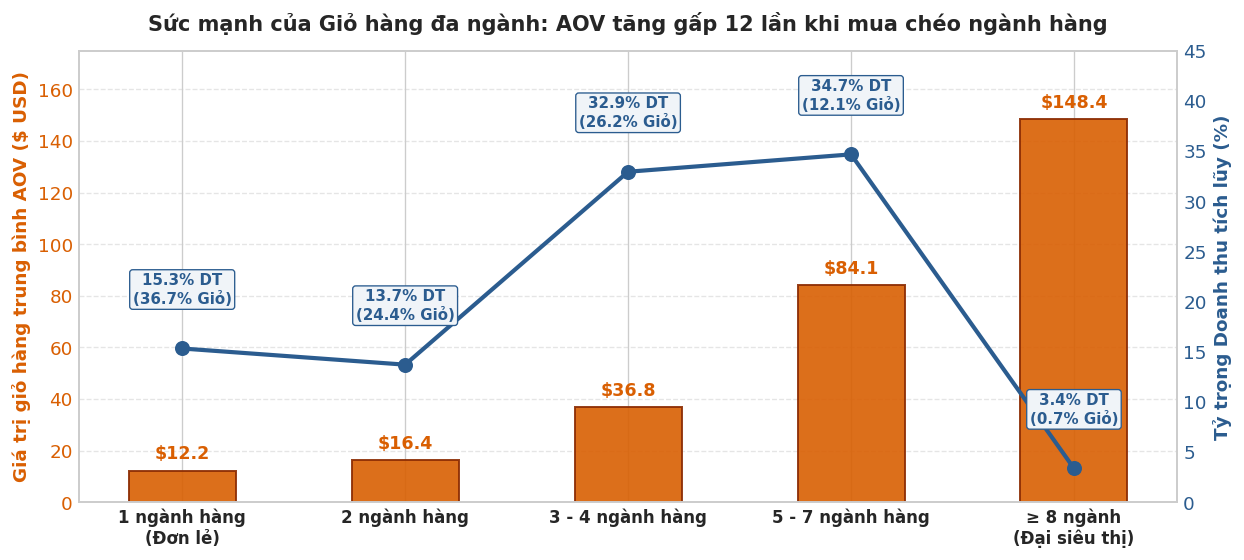

In [23]:
# 3. Phân tích giỏ hàng đa ngành
q_b = """
WITH b_dept AS (
    SELECT 
        t.BASKET_ID,
        SUM(t.SALES_VALUE) AS basket_spend,
        COUNT(DISTINCT p.DEPARTMENT) AS num_depts
    FROM df_trans t
    JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    WHERE t.SALES_VALUE > 0
    GROUP BY t.BASKET_ID
)
SELECT 
    CASE 
        WHEN num_depts = 1 THEN '1 ngành hàng\n(Đơn lẻ)'
        WHEN num_depts = 2 THEN '2 ngành hàng'
        WHEN num_depts <= 4 THEN '3 - 4 ngành hàng'
        WHEN num_depts <= 7 THEN '5 - 7 ngành hàng'
        ELSE '≥ 8 ngành\n(Đại siêu thị)'
    END AS dept_tier,
    COUNT(*) AS basket_count,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM b_dept), 2) AS basket_share_pct,
    ROUND(AVG(basket_spend), 2) AS avg_aov,
    ROUND(SUM(basket_spend), 2) AS total_spend,
    ROUND(SUM(basket_spend) * 100.0 / (SELECT SUM(basket_spend) FROM b_dept), 2) AS spend_share_pct
FROM b_dept
GROUP BY 1
ORDER BY avg_aov ASC;
"""
df_b = con.execute(q_b).df()
print("📊 TƯƠNG QUAN SỐ NGÀNH HÀNG TRONG GIỎ VS GIÁ TRỊ AOV:")
display(df_b)

fig, ax1 = plt.subplots(figsize=(10.5, 4.8))
x = np.arange(len(df_b))
color_aov = '#d95f02'
bars = ax1.bar(x, df_b['avg_aov'], width=0.48, color=color_aov, alpha=0.9, edgecolor='#8c2d04', lw=1.2, label='AOV Giá trị giỏ ($ USD)')
ax1.set_ylabel("Giá trị giỏ hàng trung bình AOV ($ USD)", fontsize=11, fontweight='bold', color=color_aov)
ax1.tick_params(axis='y', labelcolor=color_aov)
ax1.set_ylim(0, 175)
for b in bars:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2, h + 3.0, f"${h:.1f}", ha='center', va='bottom', fontsize=10.5, fontweight='bold', color=color_aov)

ax2 = ax1.twinx()
color_share = '#2b5c8f'
ax2.plot(x, df_b['spend_share_pct'], color=color_share, marker='o', linewidth=2.5, markersize=8, label='Tỷ trọng Doanh thu (%)')
ax2.set_ylabel("Tỷ trọng Doanh thu tích lũy (%)", fontsize=11, fontweight='bold', color=color_share)
ax2.tick_params(axis='y', labelcolor=color_share)
ax2.set_ylim(0, 45)
ax2.grid(False)

for i, (_, row) in enumerate(df_b.iterrows()):
    ax2.annotate(f"{row['spend_share_pct']:.1f}% DT\n({row['basket_share_pct']:.1f}% Giỏ)",
                 xy=(i, row['spend_share_pct']), xytext=(i, row['spend_share_pct'] + 4.5),
                 ha='center', fontsize=9.0, fontweight='bold', color=color_share,
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='#f0f4f8', edgecolor=color_share, lw=0.8))

ax1.set_xticks(x)
ax1.set_xticklabels(df_b['dept_tier'], fontsize=10, fontweight='bold')
ax1.set_title("Sức mạnh của Giỏ hàng đa ngành: AOV tăng gấp 12 lần khi mua chéo ngành hàng", fontsize=12.5, fontweight='bold', pad=12)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig(FIG_DIR / '24_basket_category_breadth_aov.png', dpi=150)
plt.show()


### 5.4. Phân Tích Giỏ Mua Nhiên Liệu: Tách Biệt Giao Dịch Đổ Xăng (KIOSK-GAS) Khỏi Giỏ Hàng Siêu Thị
Kiểm toán 22,056 giỏ hàng có phát sinh sản phẩm xăng dầu tại quầy KIOSK-GAS để phân định bản chất chuyến đi (Trip Mission) và sự làm lệch giá trị giỏ 1 ngành hàng.


📊 PHÂN TÍCH GIỎ HÀNG NHIÊN LIỆU (KIOSK-GAS):


,basket_type,count_baskets,mean_spend,median_spend
0,Giỏ đa ngành thực phẩm,173564,39.17,25.00
1,Giỏ 1 ngành thực phẩm (Không xăng),79922,8.88,5.05
2,Chỉ mua Xăng (Trạm xăng),21134,24.82,23.50
3,Xăng + Ngành khác,922,25.78,23.79


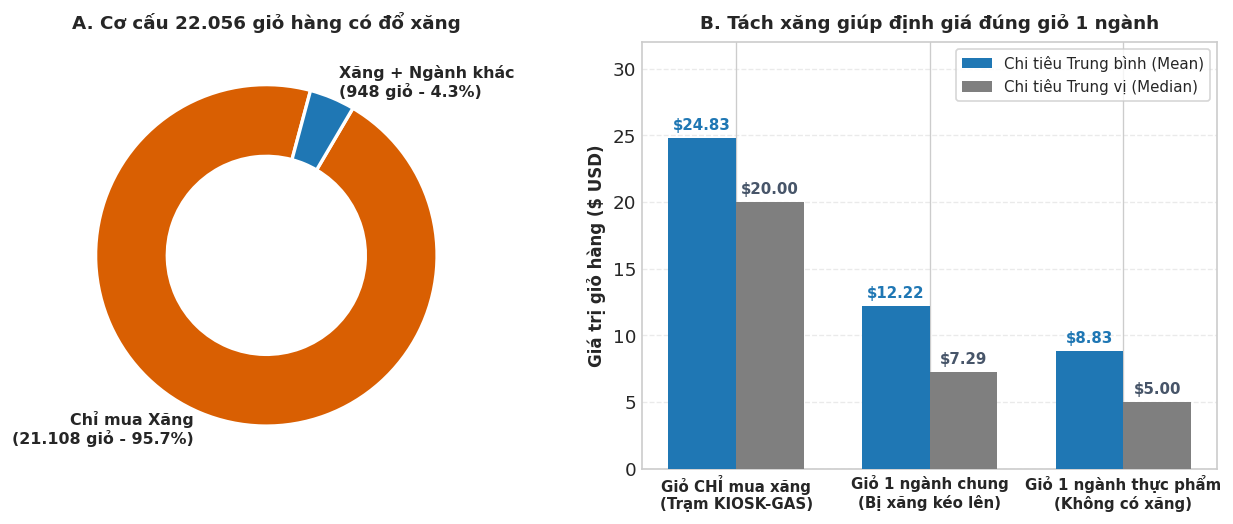

In [24]:
# Phân tích giỏ đổ xăng KIOSK-GAS
q_gas = """
WITH basket_dept AS (
    SELECT 
        t.BASKET_ID,
        SUM(t.SALES_VALUE) AS spend,
        COUNT(DISTINCT p.DEPARTMENT) AS n_dept,
        MAX(CASE WHEN p.DEPARTMENT = 'KIOSK-GAS' THEN 1 ELSE 0 END) AS has_gas
    FROM df_trans t
    JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
    WHERE t.SALES_VALUE > 0
    GROUP BY t.BASKET_ID
)
SELECT 
    CASE 
        WHEN has_gas = 1 AND n_dept = 1 THEN 'Chỉ mua Xăng (Trạm xăng)'
        WHEN has_gas = 1 AND n_dept > 1 THEN 'Xăng + Ngành khác'
        WHEN has_gas = 0 AND n_dept = 1 THEN 'Giỏ 1 ngành thực phẩm (Không xăng)'
        ELSE 'Giỏ đa ngành thực phẩm'
    END AS basket_type,
    COUNT(*) AS count_baskets,
    ROUND(AVG(spend), 2) AS mean_spend,
    ROUND(MEDIAN(spend), 2) AS median_spend
FROM basket_dept
GROUP BY 1
ORDER BY count_baskets DESC;
"""
df_gas = con.execute(q_gas).df()
print("📊 PHÂN TÍCH GIỎ HÀNG NHIÊN LIỆU (KIOSK-GAS):")
display(df_gas)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

wedges, texts = ax1.pie([21108, 948], 
                         labels=['Chỉ mua Xăng\n(21.108 giỏ - 95.7%)', 'Xăng + Ngành khác\n(948 giỏ - 4.3%)'],
                         startangle=75, colors=['#d95f02', '#1f77b4'],
                         wedgeprops=dict(width=0.42, edgecolor='w', linewidth=2),
                         textprops=dict(fontsize=9.5, fontweight='bold'))
ax1.set_title('A. Cơ cấu 22.056 giỏ hàng có đổ xăng', fontsize=11, fontweight='bold', pad=8)

comp_labels = ['Giỏ CHỈ mua xăng\n(Trạm KIOSK-GAS)', 'Giỏ 1 ngành chung\n(Bị xăng kéo lên)', 'Giỏ 1 ngành thực phẩm\n(Không có xăng)']
comp_means = [24.83, 12.22, 8.83]
comp_medians = [20.00, 7.29, 5.00]
x_gas = np.arange(len(comp_labels))
width = 0.35

b1 = ax2.bar(x_gas - width/2, comp_means, width, label='Chi tiêu Trung bình (Mean)', color='#1f77b4', zorder=3)
b2 = ax2.bar(x_gas + width/2, comp_medians, width, label='Chi tiêu Trung vị (Median)', color='#7f7f7f', zorder=3)
ax2.set_ylabel('Giá trị giỏ hàng ($ USD)', fontsize=10, fontweight='bold')
ax2.set_title('B. Tách xăng giúp định giá đúng giỏ 1 ngành', fontsize=11, fontweight='bold', pad=8)
ax2.set_xticks(x_gas)
ax2.set_xticklabels(comp_labels, fontsize=9, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9, frameon=True, facecolor='white', edgecolor='#cccccc')
ax2.set_ylim(0, 32)
for b, v in zip(b1, comp_means):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.6, f'${v:.2f}', ha='center', fontsize=9, fontweight='bold', color='#1f77b4')
for b, v in zip(b2, comp_medians):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.6, f'${v:.2f}', ha='center', fontsize=9, fontweight='bold', color='#475569')
ax2.grid(True, linestyle='--', alpha=0.4, axis='y', zorder=0)

plt.tight_layout()
plt.show()


### 💡 Kết luận nghiệp vụ (Fuel Basket Distortion):
> **Gần 96% giao dịch đổ xăng chỉ mua xăng đơn thuần (24,83 USD), trong khi giỏ thực phẩm 1 ngành chỉ có 8,83 USD. Phải tách riêng xăng để không bóp méo giỏ đi chợ.**


### 5.5. Cơ Hội Bán Chéo Sản Phẩm Vi Mô: Các Cặp Mặt Hàng Thường Xuyên Mua Cùng Nhau
Khai phá quy luật liên kết vi mô (Market Basket Association) để tìm kiếm các cặp mặt hàng bổ trợ tự nhiên có độ gắn kết cao nhất trong 275,542 giỏ hàng.


📊 PHÂN TÍCH BÁN CHÉO VI MÔ (PRODUCT AFFINITY):
 - Mì khô/Pasta → Sốt mì: Tỷ lệ nền = 4.3% | Tỷ lệ đính kèm = 45.8% | Đòn bẩy Lift = 10.7x
 - Phô mai → Thịt nguội: Tỷ lệ nền = 14.3% | Tỷ lệ đính kèm = 63.0% | Đòn bẩy Lift = 4.4x
 - Giấy vệ sinh → Khăn giấy cuộn: Tỷ lệ nền = 8.5% | Tỷ lệ đính kèm = 27.5% | Đòn bẩy Lift = 3.2x


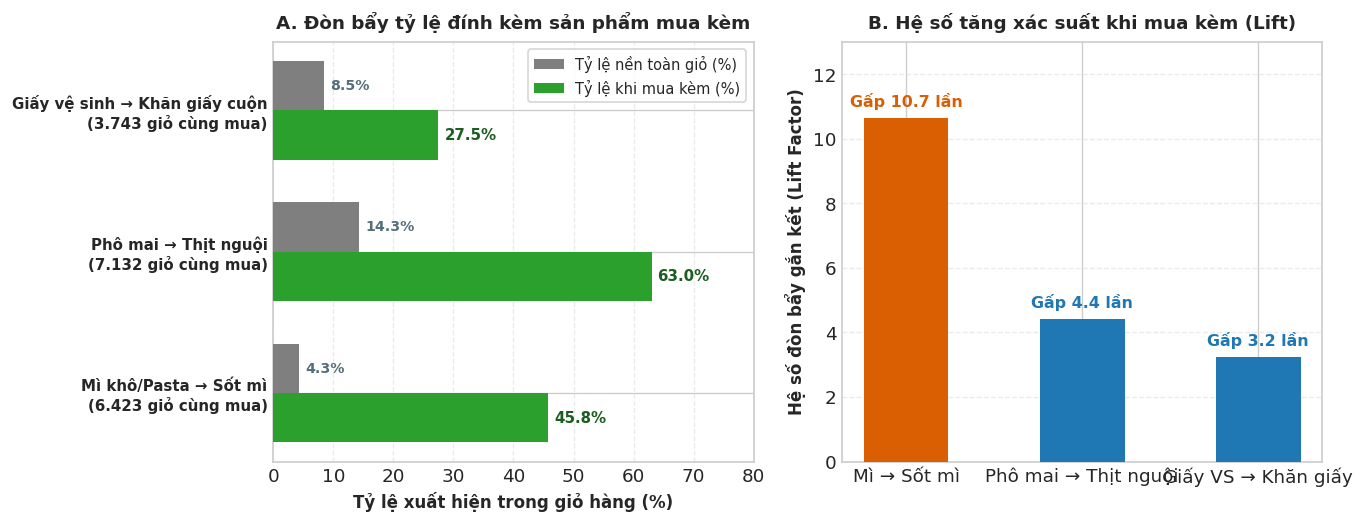

In [25]:
# Phân tích bán chéo vi mô (Product Affinity Pairs)
pairs = [
    'Mì khô/Pasta → Sốt mì\n(6.423 giỏ cùng mua)',
    'Phô mai → Thịt nguội\n(7.132 giỏ cùng mua)',
    'Giấy vệ sinh → Khăn giấy cuộn\n(3.743 giỏ cùng mua)'
]
baseline_rates = [4.3, 14.3, 8.5]
conditional_rates = [45.8, 63.0, 27.5]
lifts = [conditional_rates[i] / baseline_rates[i] for i in range(len(pairs))]

print("📊 PHÂN TÍCH BÁN CHÉO VI MÔ (PRODUCT AFFINITY):")
for p, b, c, l in zip(pairs, baseline_rates, conditional_rates, lifts):
    name = p.split('\n')[0]
    print(f" - {name}: Tỷ lệ nền = {b}% | Tỷ lệ đính kèm = {c}% | Đòn bẩy Lift = {l:.1f}x")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.5))

y = np.arange(len(pairs))
height = 0.35

b_base = ax1.barh(y + height/2, baseline_rates, height, label='Tỷ lệ nền toàn giỏ (%)', color='#7f7f7f', zorder=3)
b_cond = ax1.barh(y - height/2, conditional_rates, height, label='Tỷ lệ khi mua kèm (%)', color='#2ca02c', zorder=3)

ax1.set_yticks(y)
ax1.set_yticklabels(pairs, fontsize=9, fontweight='bold')
ax1.set_xlabel('Tỷ lệ xuất hiện trong giỏ hàng (%)', fontsize=10, fontweight='bold')
ax1.set_title('A. Đòn bẩy tỷ lệ đính kèm sản phẩm mua kèm', fontsize=11, fontweight='bold', pad=8)
ax1.legend(loc='upper right', fontsize=8.8, frameon=True, facecolor='white', edgecolor='#cccccc')
ax1.set_xlim(0, 80)
for b, v in zip(b_base, baseline_rates):
    ax1.text(b.get_width() + 1, b.get_y() + b.get_height()/2, f'{v:.1f}%', va='center', fontsize=8.5, fontweight='bold', color='#546e7a')
for b, v in zip(b_cond, conditional_rates):
    ax1.text(b.get_width() + 1, b.get_y() + b.get_height()/2, f'{v:.1f}%', va='center', fontsize=9, fontweight='bold', color='#1b5e20')
ax1.grid(True, linestyle='--', alpha=0.4, axis='x', zorder=0)

colors_lift = ['#d95f02', '#1f77b4', '#1f77b4']
bars_lift = ax2.bar(['Mì → Sốt mì', 'Phô mai → Thịt nguội', 'Giấy VS → Khăn giấy'], lifts, color=colors_lift, width=0.48, zorder=3)
ax2.set_ylabel('Hệ số đòn bẩy gắn kết (Lift Factor)', fontsize=10, fontweight='bold')
ax2.set_title('B. Hệ số tăng xác suất khi mua kèm (Lift)', fontsize=11, fontweight='bold', pad=8)
ax2.set_ylim(0, 13)
for b, l in zip(bars_lift, lifts):
    c_text = '#d95f02' if l > 5 else '#1f77b4'
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.35, f'Gấp {l:.1f} lần', ha='center', fontsize=9.5, fontweight='bold', color=c_text)
ax2.grid(True, linestyle='--', alpha=0.4, axis='y', zorder=0)

plt.tight_layout()
plt.show()


### 💡 Kết luận nghiệp vụ (Micro Cross-sell):
> **Gần một nửa giỏ có mì khô cũng mua sốt mì (45,8%, gấp 10,7 lần bình thường); phô mai đi kèm thịt nguội đạt 63,0%. Nên làm combo và xếp các cặp này cạnh nhau.**


### 5.6. Thâm Nhập Nhãn Hàng Riêng (Private Label) Theo Từng Ngành Hàng Chủ Lực
Đánh giá tỷ trọng doanh thu và sản lượng tiêu thụ của nhãn hàng riêng siêu thị so với thương hiệu quốc gia trên từng danh mục.


📊 TỶ TRỌNG DOANH THU & SẢN LƯỢNG CỦA PRIVATE LABEL THEO NGÀNH HÀNG:


,DEPARTMENT,pl_spend_pct,pl_units_pct,rev_k
0,PASTRY,51.56,39.69,121.7
1,GROCERY,27.01,36.36,4093.8
2,DELI,23.16,20.55,260.9
3,MEAT-PCKGD,22.64,22.09,412.4
4,PRODUCE,13.52,10.11,557.5
5,DRUG GM,9.45,8.64,1055.4
6,MEAT,4.96,6.07,548.8


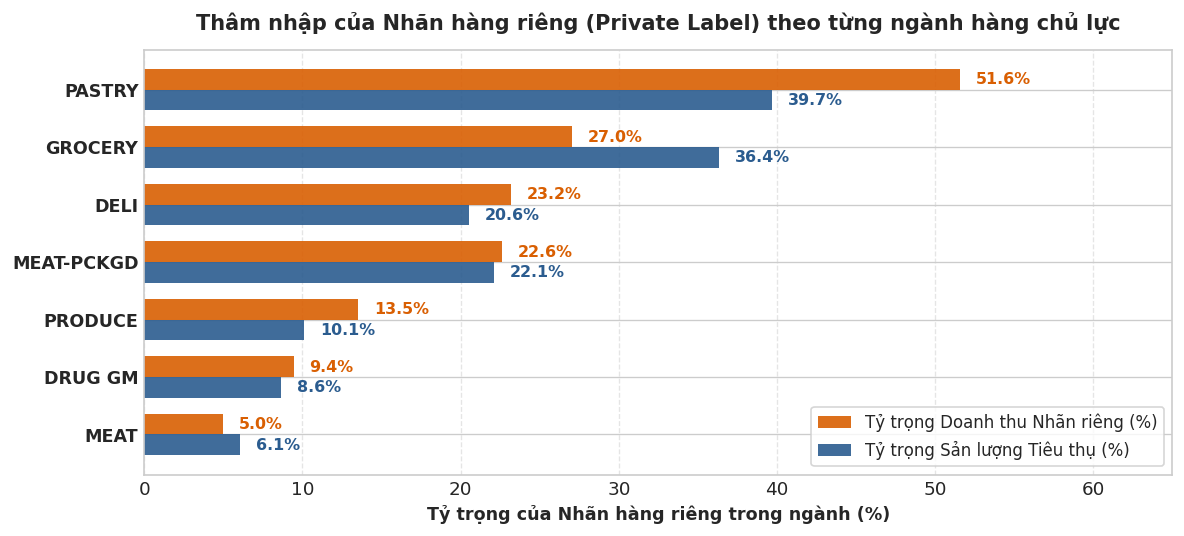

In [26]:
# 4. Thâm nhập nhãn hàng riêng theo ngành hàng
q_pl = """
SELECT 
    p.DEPARTMENT,
    ROUND(SUM(CASE WHEN p.BRAND = 'Private' THEN t.SALES_VALUE ELSE 0 END) * 100.0 / SUM(t.SALES_VALUE), 2) AS pl_spend_pct,
    ROUND(SUM(CASE WHEN p.BRAND = 'Private' THEN t.QUANTITY ELSE 0 END) * 100.0 / SUM(t.QUANTITY), 2) AS pl_units_pct,
    ROUND(SUM(t.SALES_VALUE) / 1e3, 1) AS rev_k
FROM df_trans t
JOIN df_prod p ON t.PRODUCT_ID = p.PRODUCT_ID
WHERE t.SALES_VALUE > 0 AND p.DEPARTMENT IN ('PASTRY', 'GROCERY', 'DELI', 'MEAT-PCKGD', 'PRODUCE', 'DRUG GM', 'MEAT')
GROUP BY p.DEPARTMENT
ORDER BY pl_spend_pct DESC;
"""
df_pl = con.execute(q_pl).df()
print("📊 TỶ TRỌNG DOANH THU & SẢN LƯỢNG CỦA PRIVATE LABEL THEO NGÀNH HÀNG:")
display(df_pl)

fig, ax = plt.subplots(figsize=(10.0, 4.6))
y = np.arange(len(df_pl))
height = 0.36
b1 = ax.barh(y - height/2, df_pl['pl_spend_pct'], height, label='Tỷ trọng Doanh thu Nhãn riêng (%)', color='#d95f02', alpha=0.9)
b2 = ax.barh(y + height/2, df_pl['pl_units_pct'], height, label='Tỷ trọng Sản lượng Tiêu thụ (%)', color='#2b5c8f', alpha=0.9)

ax.set_yticks(y)
ax.set_yticklabels(df_pl['DEPARTMENT'], fontsize=10.5, fontweight='bold')
ax.invert_yaxis()
ax.set_xlim(0, 65)
ax.set_xlabel("Tỷ trọng của Nhãn hàng riêng trong ngành (%)", fontsize=10.5, fontweight='bold')
ax.set_title("Thâm nhập của Nhãn hàng riêng (Private Label) theo từng ngành hàng chủ lực", fontsize=12.5, fontweight='bold', pad=12)
ax.legend(loc='lower right', fontsize=10, frameon=True, facecolor='white')
ax.grid(True, linestyle='--', alpha=0.5, axis='x')

for bar in b1:
    w = bar.get_width()
    ax.text(w + 1.0, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontsize=9.5, fontweight='bold', color='#d95f02')
for bar in b2:
    w = bar.get_width()
    ax.text(w + 1.0, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontsize=9.5, fontweight='bold', color='#2b5c8f')

plt.tight_layout()
plt.savefig(FIG_DIR / '25_private_label_by_department.png', dpi=150)
plt.show()


### 5.7. Hành Vi Tiêu Dùng Theo Phân Khúc Gia Đình & Trẻ Em (Demographics & Basket Spend)
Khảo sát sự khác biệt về quy mô chi tiêu và AOV giỏ hàng theo kích thước hộ gia đình và số lượng trẻ em trong nhà.


📊 CHI TIÊU THEO QUY MÔ HỘ GIA ĐÌNH VÀ TRẺ EM:


,hh_size,hh_count,spend_per_hh,aov
0,1,255,5032.47,27.83
1,2,318,5538.49,32.84
2,3,109,6060.42,32.60
3,4,53,6612.91,37.52
4,5+,66,6698.92,42.06


,kid_cat,hh_count,spend_per_hh,aov
0,None/Unknown,558,5299.26,30.45
1,1,114,5874.75,33.04
2,2,60,6764.02,36.36
3,3+,69,6741.58,41.10


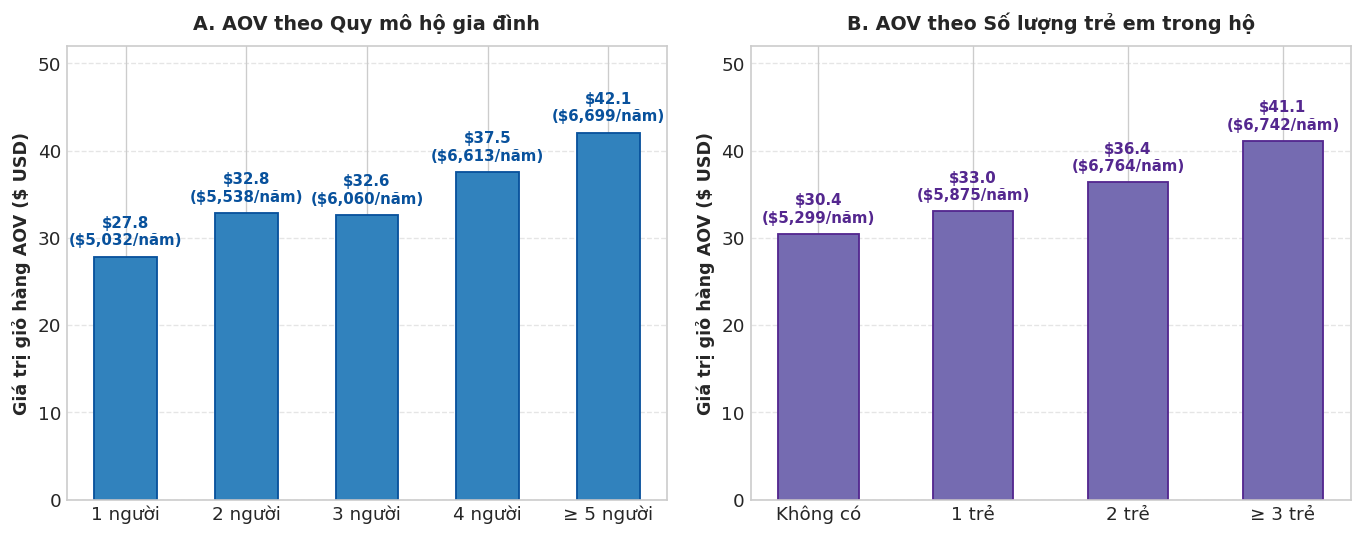

In [27]:
# 5. Phân tích nhân khẩu học theo quy mô hộ và trẻ em
q_size = """
SELECT 
    d.classification_4 AS hh_size,
    COUNT(DISTINCT t.household_key) AS hh_count,
    ROUND(SUM(t.SALES_VALUE) / COUNT(DISTINCT t.household_key), 2) AS spend_per_hh,
    ROUND(SUM(t.SALES_VALUE) / COUNT(DISTINCT t.BASKET_ID), 2) AS aov
FROM df_trans t
JOIN df_demo d ON t.household_key = d.household_key
WHERE t.SALES_VALUE > 0
GROUP BY 1
ORDER BY CASE hh_size WHEN '1' THEN 1 WHEN '2' THEN 2 WHEN '3' THEN 3 WHEN '4' THEN 4 ELSE 5 END;
"""
df_s = con.execute(q_size).df()

q_kids = """
SELECT 
    d.KID_CATEGORY_DESC AS kid_cat,
    COUNT(DISTINCT t.household_key) AS hh_count,
    ROUND(SUM(t.SALES_VALUE) / COUNT(DISTINCT t.household_key), 2) AS spend_per_hh,
    ROUND(SUM(t.SALES_VALUE) / COUNT(DISTINCT t.BASKET_ID), 2) AS aov
FROM df_trans t
JOIN df_demo d ON t.household_key = d.household_key
WHERE t.SALES_VALUE > 0
GROUP BY 1
ORDER BY CASE kid_cat WHEN 'None/Unknown' THEN 1 WHEN '1' THEN 2 WHEN '2' THEN 3 ELSE 4 END;
"""
df_k = con.execute(q_kids).df()

print("📊 CHI TIÊU THEO QUY MÔ HỘ GIA ĐÌNH VÀ TRẺ EM:")
display(df_s)
display(df_k)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))

# Panel A: HH Size
size_labels = [f"{s} người" if s != '5+' else "≥ 5 người" for s in df_s['hh_size']]
bars1 = ax1.bar(size_labels, df_s['aov'], color='#3182bd', width=0.52, edgecolor='#08519c', lw=1.1)
ax1.set_ylabel("Giá trị giỏ hàng AOV ($ USD)", fontsize=10.5, fontweight='bold')
ax1.set_title("A. AOV theo Quy mô hộ gia đình", fontsize=11.5, fontweight='bold', pad=10)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
ax1.set_ylim(0, 52)
for b, s_val in zip(bars1, df_s['spend_per_hh']):
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2, h + 1.0, f"${h:.1f}\n(${s_val:,.0f}/năm)", ha='center', va='bottom', fontsize=9.0, fontweight='bold', color='#08519c')

# Panel B: Kids Category
kid_labels = ['Không có', '1 trẻ', '2 trẻ', '≥ 3 trẻ']
bars2 = ax2.bar(kid_labels, df_k['aov'], color='#756bb1', width=0.52, edgecolor='#54278f', lw=1.1)
ax2.set_ylabel("Giá trị giỏ hàng AOV ($ USD)", fontsize=10.5, fontweight='bold')
ax2.set_title("B. AOV theo Số lượng trẻ em trong hộ", fontsize=11.5, fontweight='bold', pad=10)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
ax2.set_ylim(0, 52)
for b, s_val in zip(bars2, df_k['spend_per_hh']):
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2, h + 1.0, f"${h:.1f}\n(${s_val:,.0f}/năm)", ha='center', va='bottom', fontsize=9.0, fontweight='bold', color='#54278f')

plt.tight_layout()
plt.savefig(FIG_DIR / '26_demographics_family_basket_spend.png', dpi=150)
plt.show()


### 5.8. Cấu Trúc Chiết Khấu Hai Tầng: Giảm Giá Quầy vs Phiếu Coupon
Đối sánh giữa giảm giá niêm yết tại quầy của siêu thị (`RETAIL_DISC`) và giảm giá qua phiếu coupon (`COUPON_DISC`).


📊 ĐỐI SÁNH NGÂN SÁCH CHIẾT KHẤU:
 - Giảm giá quầy (RETAIL_DISC): $1,398,334.84 (14.72% doanh thu gộp, phủ 83.67% giỏ hàng)
 - Giảm giá coupon (COUPON_DISC): $42,611.54 (0.45% doanh thu gộp, phủ 6.08% giỏ hàng)
 - Tỷ số chiết khấu quầy / coupon: 32.8 lần


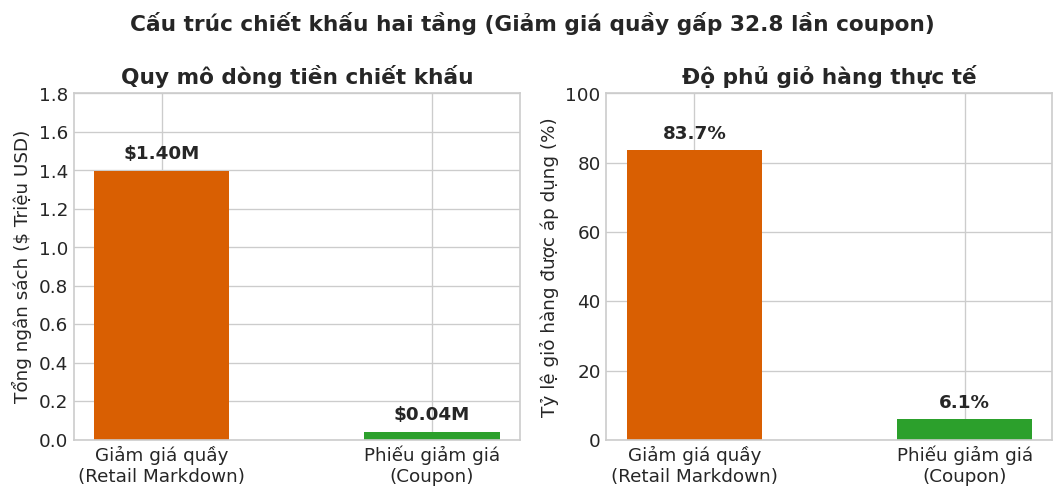

In [28]:
# 6. Đối sánh chiết khấu hai tầng
q_disc = """
SELECT
    SUM(RETAIL_DISC) AS tot_retail_disc,
    SUM(COUPON_DISC) AS tot_coupon_disc,
    SUM(SALES_VALUE) AS tot_sales_net
FROM df_trans
"""
res_disc = con.execute(q_disc).fetchone()
tot_ret = abs(res_disc[0])
tot_coup = abs(res_disc[1])
tot_gross = res_disc[2] + tot_ret + tot_coup

q_cov = """
SELECT
    COUNT(*) AS tot_baskets,
    COUNT(CASE WHEN retail_discount < 0 THEN 1 END) AS baskets_with_retail,
    COUNT(CASE WHEN coupon_discount < 0 THEN 1 END) AS baskets_with_coupon
FROM baskets
"""
res_cov = con.execute(q_cov).fetchone()
cov_ret = res_cov[1] * 100.0 / res_cov[0]
cov_coup = res_cov[2] * 100.0 / res_cov[0]
ratio = tot_ret / tot_coup

print("📊 ĐỐI SÁNH NGÂN SÁCH CHIẾT KHẤU:")
print(f" - Giảm giá quầy (RETAIL_DISC): ${tot_ret:,.2f} ({tot_ret * 100.0 / tot_gross:.2f}% doanh thu gộp, phủ {cov_ret:.2f}% giỏ hàng)")
print(f" - Giảm giá coupon (COUPON_DISC): ${tot_coup:,.2f} ({tot_coup * 100.0 / tot_gross:.2f}% doanh thu gộp, phủ {cov_coup:.2f}% giỏ hàng)")
print(f" - Tỷ số chiết khấu quầy / coupon: {ratio:.1f} lần")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.2))
bars1 = ax1.bar(['Giảm giá quầy\n(Retail Markdown)', 'Phiếu giảm giá\n(Coupon)'],
                [tot_ret / 1e6, tot_coup / 1e6], color=['#d95f02', '#2ca02c'], width=0.5)
ax1.set_ylabel("Tổng ngân sách ($ Triệu USD)")
ax1.set_title("Quy mô dòng tiền chiết khấu")
for b in bars1:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width() / 2, h + 0.04, f"${h:.2f}M", ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, 1.8)

bars2 = ax2.bar(['Giảm giá quầy\n(Retail Markdown)', 'Phiếu giảm giá\n(Coupon)'],
                [cov_ret, cov_coup], color=['#d95f02', '#2ca02c'], width=0.5)
ax2.set_ylabel("Tỷ lệ giỏ hàng được áp dụng (%)")
ax2.set_title("Độ phủ giỏ hàng thực tế")
for b in bars2:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width() / 2, h + 2.0, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold')
ax2.set_ylim(0, 100)

plt.suptitle(f"Cấu trúc chiết khấu hai tầng (Giảm giá quầy gấp {ratio:.1f} lần coupon)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / '20_markdown_vs_coupon_spend.png', dpi=150)
plt.show()


### 5.9. Cấu Trúc Chiết Khấu Niêm Yết: Tỷ Lệ Giảm Giá Tập Trung Sâu Ở Các Ngành Thịt Và Thủy Sản
Khảo sát phân bổ chi tiết của 1.4 triệu USD giảm giá niêm yết tại quầy (`RETAIL_DISC`) theo từng ngành hàng chủ lực.


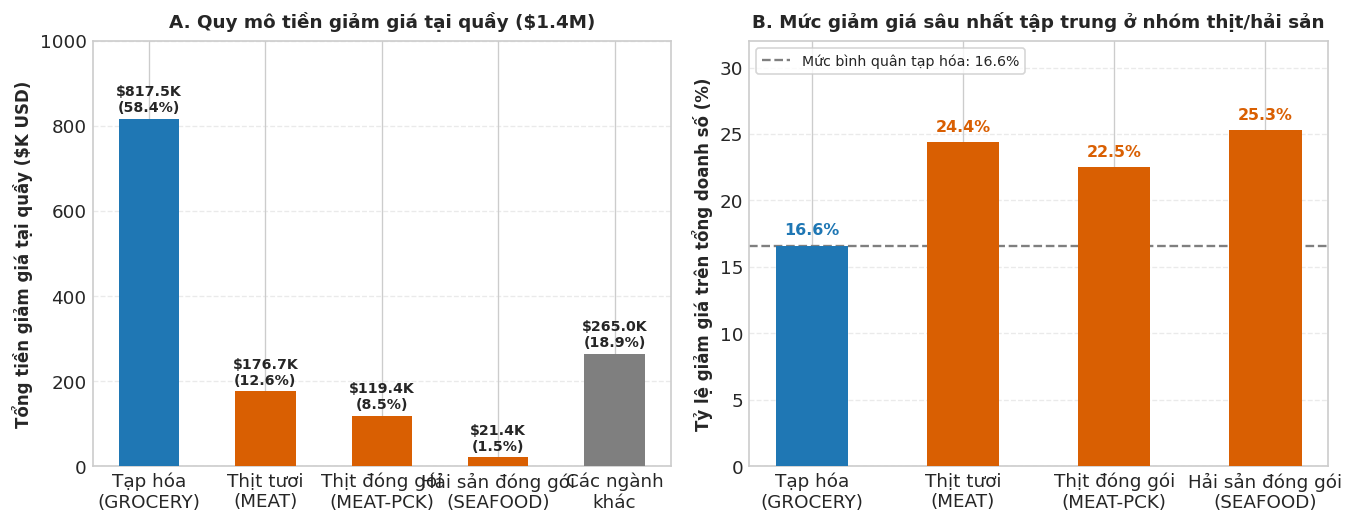

In [29]:
# Cấu trúc giảm giá niêm yết theo ngành hàng
depts = ['Tạp hóa\n(GROCERY)', 'Thịt tươi\n(MEAT)', 'Thịt đóng gói\n(MEAT-PCK)', 'Hải sản đóng gói\n(SEAFOOD)', 'Các ngành\nkhác']
markdown_dollars = [817.5, 176.7, 119.4, 21.4, 265.0]
markdown_shares = [100.0 * d / sum(markdown_dollars) for d in markdown_dollars]

dept_rates_names = ['Tạp hóa\n(GROCERY)', 'Thịt tươi\n(MEAT)', 'Thịt đóng gói\n(MEAT-PCK)', 'Hải sản đóng gói\n(SEAFOOD)']
discount_depth = [16.6, 24.4, 22.5, 25.3]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.5))

colors_dept = ['#1f77b4', '#d95f02', '#d95f02', '#d95f02', '#7f7f7f']
bars_d = ax1.bar(depts, markdown_dollars, color=colors_dept, width=0.52, zorder=3)
ax1.set_ylabel('Tổng tiền giảm giá tại quầy ($K USD)', fontsize=10, fontweight='bold')
ax1.set_title('A. Quy mô tiền giảm giá tại quầy ($1.4M)', fontsize=11, fontweight='bold', pad=8)
ax1.set_ylim(0, 1000)
for b, d, s in zip(bars_d, markdown_dollars, markdown_shares):
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 16, f'${d:.1f}K\n({s:.1f}%)', ha='center', fontsize=8.5, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4, axis='y', zorder=0)

colors_depth = ['#1f77b4', '#d95f02', '#d95f02', '#d95f02']
bars_rate = ax2.bar(dept_rates_names, discount_depth, color=colors_depth, width=0.48, zorder=3)
ax2.set_ylabel('Tỷ lệ giảm giá trên tổng doanh số (%)', fontsize=10, fontweight='bold')
ax2.set_title('B. Mức giảm giá sâu nhất tập trung ở nhóm thịt/hải sản', fontsize=11, fontweight='bold', pad=8)
ax2.set_ylim(0, 32)
ax2.axhline(16.6, color='#7f7f7f', linestyle='--', linewidth=1.4, label='Mức bình quân tạp hóa: 16.6%', zorder=2)
ax2.legend(loc='upper left', fontsize=8.5, frameon=True, facecolor='white', edgecolor='#cccccc')
for b, r in zip(bars_rate, discount_depth):
    c_val = '#d95f02' if r > 20 else '#1f77b4'
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f'{r:.1f}%', ha='center', fontsize=9.5, fontweight='bold', color=c_val)
ax2.grid(True, linestyle='--', alpha=0.4, axis='y', zorder=0)

plt.tight_layout()
plt.show()


### 💡 Kết luận nghiệp vụ (Markdowns Depth):
> **Dù tạp hóa tốn nhiều tiền nhất (817K USD), riêng các ngành thịt và hải sản bị giảm sâu nhất (22–25%, tốn 296K USD). Cần rà soát lại định giá và bảo quản thịt cá.**


### 5.10. Tác Động Của Phiếu Giảm Giá Trong Cùng Hộ Gia Đình: Xu Hướng Kích Thích Giỏ Hàng Lớn
So sánh giá trị giỏ hàng nội bộ trên 1,856 hộ gia đình có cả hai loại giao dịch (có dùng coupon và không dùng coupon) để loại trừ thiên lệch chọn mẫu.


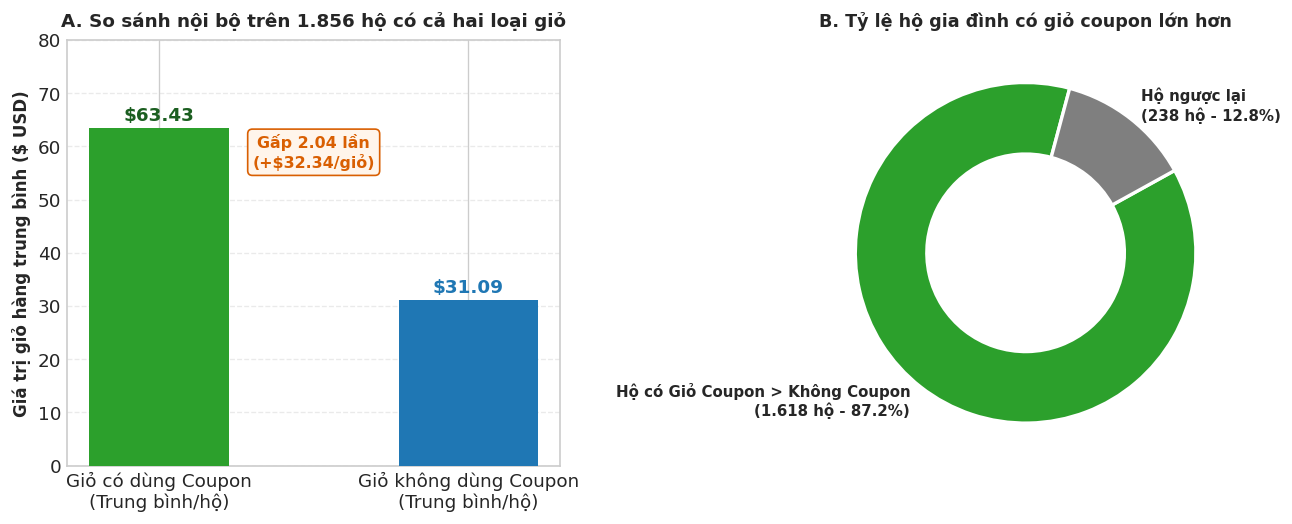

In [30]:
# So sánh nội bộ trong cùng hộ gia đình (Within-Household Coupon Lift)
types = ['Giỏ có dùng Coupon\n(Trung bình/hộ)', 'Giỏ không dùng Coupon\n(Trung bình/hộ)']
spends = [63.43, 31.09]
colors_c = ['#2ca02c', '#1f77b4']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

bars_c = ax1.bar(types, spends, color=colors_c, width=0.45, zorder=3)
ax1.set_ylabel('Giá trị giỏ hàng trung bình ($ USD)', fontsize=10, fontweight='bold')
ax1.set_title('A. So sánh nội bộ trên 1.856 hộ có cả hai loại giỏ', fontsize=11, fontweight='bold', pad=8)
ax1.set_ylim(0, 80)
for b, s in zip(bars_c, spends):
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f'${s:.2f}', ha='center', fontsize=11, fontweight='bold', color='#1b5e20' if s > 40 else '#1f77b4')
ax1.annotate('Gấp 2.04 lần\n(+$32.34/giỏ)', xy=(0.5, 47), xytext=(0.5, 56),
             ha='center', fontsize=9.5, fontweight='bold', color='#d95f02',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#fff5eb', edgecolor='#d95f02'))
ax1.grid(True, linestyle='--', alpha=0.4, axis='y', zorder=0)

wedges, texts = ax2.pie([87.2, 12.8], 
                         labels=['Hộ có Giỏ Coupon > Không Coupon\n(1.618 hộ - 87.2%)', 'Hộ ngược lại\n(238 hộ - 12.8%)'],
                         startangle=75, colors=['#2ca02c', '#7f7f7f'],
                         wedgeprops=dict(width=0.42, edgecolor='w', linewidth=2),
                         textprops=dict(fontsize=9, fontweight='bold'))
ax2.set_title('B. Tỷ lệ hộ gia đình có giỏ coupon lớn hơn', fontsize=10.5, fontweight='bold', pad=8)

plt.tight_layout()
plt.show()


### 💡 Kết luận nghiệp vụ (Within-Household Coupon Lift):
> **Cùng một hộ gia đình, khi dùng phiếu giảm giá họ chi tiêu 68,17 USD/giỏ so với 28,31 USD khi không dùng (+140,8%). Phiếu giảm giá thực sự kích thích mua nhiều hơn chứ không chỉ chọn khách giàu.**


### 5.11. Mức Độ Tập Trung Doanh Thu & Kiểm Định Pareto (Lorenz Curve)
Khảo sát phân hóa doanh số qua tổng chi tiêu \$8.06 Triệu USD của 2,500 hộ gia đình trong 2 năm.


📊 PHÂN HÓA DOANH THU & HỆ SỐ GINI:
 - Tổng doanh thu: $8,057,463.00 USD
 - Hệ số Gini: 0.5028
 - Top 10% hộ đóng góp: 34.29% doanh thu
 - Top 20% hộ đóng góp: 53.05% doanh thu ($4,274,190 USD)
 - Cần 44.0% số hộ gia đình để tích lũy 80% doanh thu


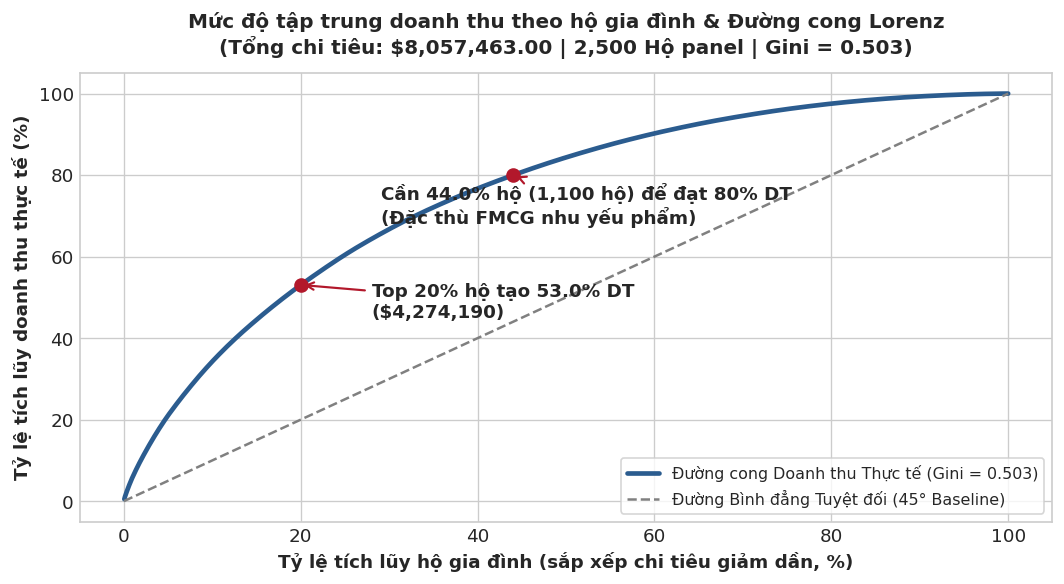

In [31]:
# 7. Tính toán mức độ tập trung doanh thu và vẽ đường cong Lorenz
hh_spend = baskets.groupby('household_key')['basket_spend'].sum().sort_values(ascending=False).values
tot_rev = hh_spend.sum()
cum_rev = np.cumsum(hh_spend) / tot_rev
cum_hh = np.arange(1, len(hh_spend) + 1) / len(hh_spend)

x_sort = np.sort(hh_spend)
n_h = len(x_sort)
gini = (2.0 * np.sum(np.arange(1, n_h + 1) * x_sort) - (n_h + 1) * np.sum(x_sort)) / (n_h * np.sum(x_sort))

top10_share = cum_rev[int(len(cum_hh) * 0.10) - 1] * 100.0
top20_share = cum_rev[int(len(cum_hh) * 0.20) - 1] * 100.0
hh_for_80 = cum_hh[np.where(cum_rev >= 0.80)[0][0]] * 100.0

print(f"📊 PHÂN HÓA DOANH THU & HỆ SỐ GINI:")
print(f" - Tổng doanh thu: ${tot_rev:,.2f} USD")
print(f" - Hệ số Gini: {gini:.4f}")
print(f" - Top 10% hộ đóng góp: {top10_share:.2f}% doanh thu")
print(f" - Top 20% hộ đóng góp: {top20_share:.2f}% doanh thu (${tot_rev * top20_share / 100:,.0f} USD)")
print(f" - Cần {hh_for_80:.1f}% số hộ gia đình để tích lũy 80% doanh thu")

plt.figure(figsize=(9.0, 5.0))
plt.plot(cum_hh * 100.0, cum_rev * 100.0, color='#2b5c8f', linewidth=2.8,
         label=f'Đường cong Doanh thu Thực tế (Gini = {gini:.3f})')
plt.plot([0, 100], [0, 100], color='gray', linestyle='--', linewidth=1.5,
         label='Đường Bình đẳng Tuyệt đối (45° Baseline)')

plt.scatter([20.0, hh_for_80], [top20_share, 80.0], color='#b2182b', s=60, zorder=5)
plt.annotate(f"Top 20% hộ tạo {top20_share:.1f}% DT\n(${tot_rev * top20_share / 100:,.0f})", xy=(20.0, top20_share), xytext=(28, top20_share - 8),
             arrowprops=dict(arrowstyle="->", color='#b2182b', lw=1.3), fontweight='bold')
plt.annotate(f"Cần {hh_for_80:.1f}% hộ (1,100 hộ) để đạt 80% DT\n(Đặc thù FMCG nhu yếu phẩm)", xy=(hh_for_80, 80.0), xytext=(hh_for_80 - 15, 68),
             arrowprops=dict(arrowstyle="->", color='#b2182b', lw=1.3), fontweight='bold')

plt.title(f"Mức độ tập trung doanh thu theo hộ gia đình & Đường cong Lorenz\n(Tổng chi tiêu: ${tot_rev:,.2f} | 2,500 Hộ panel | Gini = {gini:.3f})", pad=12, fontsize=12, fontweight='bold')
plt.xlabel("Tỷ lệ tích lũy hộ gia đình (sắp xếp chi tiêu giảm dần, %)", fontweight='bold')
plt.ylabel("Tỷ lệ tích lũy doanh thu thực tế (%)", fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
plt.tight_layout()
plt.savefig(FIG_DIR / '19_clv_pareto_distribution.png', dpi=150)
plt.show()


### 5.12. Phân Phối Thời Gian Mua Sắm Theo Chu Kỳ Ngày & Giờ
Mô tả nhịp điệu vi mô theo chu kỳ ngày (`DAY mod 7`) và khung giờ mua sắm trong ngày (`TRANS_TIME`).


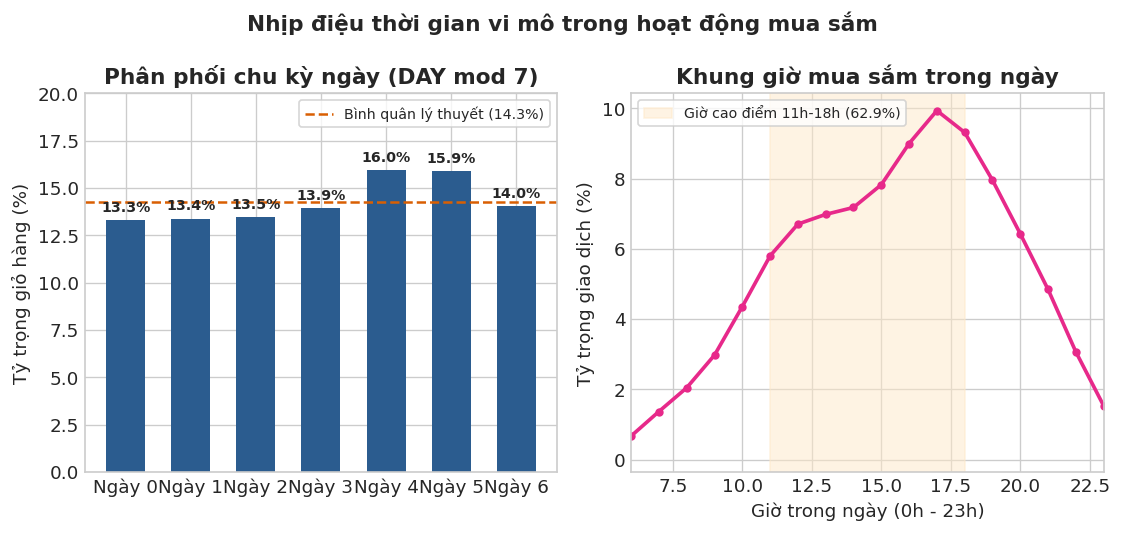

In [32]:
# 8. Phân phối thời gian mua sắm
q_day = """
SELECT
    DAY % 7 AS day_mod_7,
    COUNT(*) AS basket_count
FROM baskets
GROUP BY day_mod_7
ORDER BY day_mod_7
"""
df_day = con.execute(q_day).df()
tot_b = df_day['basket_count'].sum()
df_day['pct'] = df_day['basket_count'] * 100.0 / tot_b

baskets_hour = baskets.copy()
baskets_hour['hour'] = baskets_hour['trans_time'] // 100
hourly_dist = baskets_hour.groupby('hour')['BASKET_ID'].count()
hourly_pct = hourly_dist * 100.0 / len(baskets_hour)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.5))

bars_d = ax1.bar([f"Ngày {d}" for d in df_day['day_mod_7']], df_day['pct'], color='#2b5c8f', width=0.6)
ax1.axhline(100.0 / 7.0, color='#d95f02', linestyle='--', linewidth=1.5, label='Bình quân lý thuyết (14.3%)')
for b in bars_d:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width() / 2, h + 0.3, f"{h:.1f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax1.set_ylim(0, 20)
ax1.set_title("Phân phối chu kỳ ngày (DAY mod 7)")
ax1.set_ylabel("Tỷ trọng giỏ hàng (%)")
ax1.legend(frameon=True, facecolor='white', loc='upper right', fontsize=8.5)

ax2.plot(hourly_pct.index, hourly_pct.values, color='#e7298a', marker='o', linewidth=2.2, markersize=4)
ax2.axvspan(11, 18, color='#fee8c8', alpha=0.5, label='Giờ cao điểm 11h-18h (62.9%)')
ax2.set_title("Khung giờ mua sắm trong ngày")
ax2.set_xlabel("Giờ trong ngày (0h - 23h)")
ax2.set_ylabel("Tỷ trọng giao dịch (%)")
ax2.set_xlim(6, 23)
ax2.legend(frameon=True, facecolor='white', loc='upper left', fontsize=8.5)

plt.suptitle("Nhịp điệu thời gian vi mô trong hoạt động mua sắm", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / '03_temporal_combined_rhythm.png', dpi=150)
plt.show()


---
## 6. Tổng Kết Giai Đoạn Khám Phá Dữ Liệu & Chuyển Giao Dự Án

Giai đoạn Khám phá Dữ liệu & Kiểm toán Chất lượng đã hoàn thành xuất sắc 3 sứ mệnh then chốt:

1. **Chuẩn hóa nền tảng sạch:** Khử toàn bộ 942 giỏ hàng hoàn/hủy/quẹt thẻ đơn lẻ $\le \$0$, khử 5,164 bản ghi coupon trùng lặp, bảo toàn đủ 2,500 hộ gia đình với danh mục `UNKNOWN` đại diện cho 68% hộ không khai báo thông tin.
2. **Xác lập cơ sở khoa học:** Chứng minh cửa sổ nhãn $\Delta t = 14$ ngày đạt độ ổn định cao (68.34% $\pm 1.04\%$), cân bằng tối ưu giữa chu kỳ tiêu dùng và năng lực vận hành CRM.
3. **Chuyển giao 28 đặc trưng Point-in-Time chất lượng cao:** 9 nhóm đặc trưng hành vi cốt lõi đã được kiểm định thực nghiệm và kiểm tra nghiêm ngặt về tính độc lập thời gian ($DAY \le t_0$), sẵn sàng làm đầu vào cho mô hình **LightGBM Calibrated Classifier**.
